# Mass-definition comparison

Same run loading, alignment and filters as `finalplots2.ipynb`. The three figures below are redrawn for each oscillon-mass definition.

- **phi** — $\rho = \rho_\phi$ (`emtensor.rho`). Mass, radius and compactness are the cached `diagnostics.npz` series. The $\ln(a)$ alignment is this series, and it is shared by the other two definitions.
- **tot** — $\rho = \rho_\phi + \rho_{\rm GB} + \rho_{g_2}$. The 5% contour is rebuilt, so radius, mass and compactness all move.
- **ms** — Misner-Sharp mass at the outer edge of the **phi** 5% contour. The stored radius is the phi volume radius. The stored mass is $8\pi M_{\rm MS}$ so it matches $\int \rho\,dV$ (`eight_pi_G = 1`). Compactness is $M_{\rm MS}/R_{\rm areal}$ at that outer point.

Saved names in `GoodFigures/` gain the suffix `_Mphi`, `_Mtot` or `_Mms`.


## 0 — Imports and output directory

In [1]:
import sys, os, re, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path.insert(0, PROJECT_ROOT)

from core.grid import Grid
from core.spacing import CubicSpacing
from core.statevector import StateVector
from matter.scalarmatter_MG import ScalarMatter
from backgrounds.sphericalbackground import FlatSphericalBackground
from bssn.oscillondiagnostic import (
    get_oscillon_diagnostic, plot_paper_diagnostics, get_oscillon_mass_definitions,
)
from bssn.EFTdiagnostic import get_eft_diagnostic

from paths import RUN_DATA
DATA_DIR = str(RUN_DATA)
FIG_DIR  = Path(os.getcwd()) / "GoodFigures"
FIG_DIR.mkdir(exist_ok=True)

print(f"DATA_DIR = {DATA_DIR}")
print(f"FIG_DIR  = {FIG_DIR}")


DATA_DIR = /lustre/hpc/astro/syildiz/VSC_home/0scillons/oscillon_runs_data
FIG_DIR  = /lustre/hpc/astro/syildiz/VSC_home/0scillons/February26Oscillons/Feb26/RunningCode/DATA/GoodFigures


## 1 — Publication style and figure-saving helper

In [2]:
plt.rcParams.update({
    "font.family":      "serif",
    "mathtext.fontset": "cm",
    "figure.dpi":       120,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
    "axes.labelsize":   23,
    "axes.titlesize":   16,
    "xtick.labelsize":  15,
    "ytick.labelsize":  15,
    "legend.fontsize":  15,
    "lines.linewidth":  2.5,
    "axes.linewidth":   3,
    "xtick.major.width": 1.3,
    "ytick.major.width": 1.3,
    "xtick.minor.width": 0.9,
    "ytick.minor.width": 0.9,
    "xtick.major.size":  5.0,
    "ytick.major.size":  5.0,
    "axes.grid":        False,
    "grid.alpha":       0.3,
    "ytick.direction":  "in",
    "xtick.direction":  "in",
})

def save_fig(fig, name):
    """Save fig as both PDF and PNG in GoodFigures/."""
    pdf_path = FIG_DIR / f"{name}.pdf"
    png_path = FIG_DIR / f"{name}.png"
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, bbox_inches="tight")
    print(f"  saved {pdf_path.name} and {png_path.name}")


## 2 — Alignment and grid parameters

Alignment is computed from the matter-density compactness and then kept fixed for all three mass definitions.

In [3]:
ALIGN_LNA      = 2.0
ALIGN_METHOD   = "last_cross"   # "min_C" or "last_cross"
LNA_MIN_SEARCH = 0.0

C_CROSS_LEVELS = {
    -0.02: 0.02,
    -0.05: 0.04,
    -0.1:  0.06,
    -0.5:  0.125,
}
C_CROSS_DEFAULT = 0.02

LN_A_COMP_MIN = 2.0
LN_A_COMP_MAX = 3.5

scalar_mu = 1
r_max     = 150
min_dr    = 1 / 16
max_dr    = 2
a_mg      = 0.2
b_mg      = 0.4
chi0      = 0.15


## 3 — Alignment helpers

In [4]:
def find_peak_lna(osc, lna_min=0.0):
    """Return ln(a) of the minimum compactness after lna_min."""
    C = osc["C"]
    ln_a = osc["ln_a"]
    mask = ln_a > lna_min
    if not np.any(mask):
        return np.nan
    idx = np.where(mask)[0]
    peak = idx[np.argmin(C[idx])]
    return ln_a[peak]

def find_last_crossing_lna(osc, level, lna_min=0.0):
    """Return ln(a) of the last time C crosses `level` (from above) after lna_min."""
    C = osc["C"]
    ln_a = osc["ln_a"]
    mask = ln_a > lna_min
    if not np.any(mask):
        return np.nan
    idx = np.where(mask)[0]
    C_sub = C[idx]
    ln_a_sub = ln_a[idx]
    above = C_sub > level
    crossings = np.where(above[:-1] & ~above[1:])[0]
    if len(crossings) == 0:
        return np.nan
    last = crossings[-1]
    frac = (level - C_sub[last+1]) / (C_sub[last] - C_sub[last+1])
    return ln_a_sub[last] * frac + ln_a_sub[last+1] * (1 - frac)

def compactness_in_window(shifted_ln_a, C, lo=LN_A_COMP_MIN, hi=LN_A_COMP_MAX):
    """Mean, min, max, std of C inside [lo, hi] on the *shifted* axis."""
    mask = (shifted_ln_a >= lo) & (shifted_ln_a <= hi)
    if not np.any(mask):
        return np.nan, np.nan, np.nan, np.nan
    c = C[mask]
    return np.mean(c), np.min(c), np.max(c), np.std(c)

def _key_sort(key):
    """Sort key for run-keys that may contain None (e.g. beta=None for linear coupling).

    Maps None -> +inf so linear runs sort after numeric beta values.
    """
    return tuple(float('inf') if v is None else v for v in key)


## 4 — Load all runs at the chosen resolution

In [5]:
######## LOADING FILTERS ########
FILTER_A_MG = 0       # None to load all
FILTER_B_MG = 0       # None to load all
FILTER_DR   = 1/24    # None to load all
# True keeps a folder whose name ends in _idfix when both exist.
# False keeps the original folder. If only one family is on disk, that one is used.
USE_IDFIX   = True
############################

# Key now includes g2 so quadratic and g2-EFT runs with the same
# (lgb, mu, beta, amp, width) but different g2 don't overwrite each other.
all_runs = {}   # key = (lgb, mu, beta, amp, width, g2)

def _is_idfix(tag):
    return str(tag).endswith("_idfix")

def _prefer_candidate(tag, span, prev_tag, prev_span):
    """Pick between two folders that parse to the same physics key."""
    new_fix = _is_idfix(tag)
    prev_fix = _is_idfix(prev_tag)
    if new_fix != prev_fix:
        return new_fix if USE_IDFIX else (not new_fix)
    return span > prev_span or (span == prev_span and tag > prev_tag)

print(f"Run family: {'idfix' if USE_IDFIX else 'original'}  (set USE_IDFIX to switch)")

for run_dir in sorted(glob.glob(os.path.join(DATA_DIR, "lgb*"))):
    tag = os.path.basename(run_dir)
    if not os.path.exists(os.path.join(run_dir, "solution.npy")):
        continue

    m_lgb = re.search(r"lgb([0-9eE.+-]+)", tag)
    m_mu  = re.search(r"mu([0-9eE.+-]+)", tag)
    m_amp = re.search(r"_amp([0-9eE.+-]+)", tag)
    m_R   = re.search(r"_R([0-9eE.+-]+)", tag)
    if not m_lgb or not m_mu:
        continue
    lgb   = float(m_lgb.group(1))
    mu    = float(m_mu.group(1))
    amp   = float(m_amp.group(1)) if m_amp else -0.02
    width = float(m_R.group(1))   if m_R   else 3.0

    m_a = re.search(r"_a([0-9eE.+-]+)_b", tag)
    m_b = re.search(r"_b([0-9eE.+-]+)_amp", tag)
    tag_a = float(m_a.group(1)) if m_a else 0.2
    tag_b = float(m_b.group(1)) if m_b else 0.4

    m_dr = re.search(r"_dr([0-9eE.+-]+)", tag)
    tag_dr = float(m_dr.group(1)) if m_dr else 0.0625

    if FILTER_A_MG is not None and abs(tag_a - FILTER_A_MG) > 1e-10:
        continue
    if FILTER_B_MG is not None and abs(tag_b - FILTER_B_MG) > 1e-10:
        continue
    if FILTER_DR is not None and abs(tag_dr - FILTER_DR) > 1e-4:
        continue

    # Derive coupling and beta from metadata.npz (authoritative source).
    # Per bssn/ModifiedGravity.py: "quadratic" (no suffix) => beta=250;
    # "quadratic_X" => beta=X; "linear" => beta=None.
    _meta_for_cpl = os.path.join(run_dir, "metadata.npz")
    _cpl_meta = None
    if os.path.exists(_meta_for_cpl):
        try:
            _md = dict(np.load(_meta_for_cpl, allow_pickle=True))
            if "coupling" in _md:
                _cpl_meta = str(_md["coupling"])
        except Exception:
            pass

    if _cpl_meta is not None:
        if _cpl_meta == "linear":
            coupling = "linear"; beta = None
        elif _cpl_meta.startswith("quadratic"):
            _parts = _cpl_meta.split("_")
            beta = float(_parts[1]) if len(_parts) > 1 else 250.0
            coupling = _cpl_meta
        else:
            coupling = _cpl_meta; beta = None
    else:
        # Fallback for runs with missing metadata: parse from tag string.
        if "_linear" in tag:
            coupling = "linear"; beta = None
        else:
            _m_beta = re.search(r"quadratic_(\d+\.?\d*)", tag)
            if _m_beta:
                beta = float(_m_beta.group(1))
                coupling = f"quadratic_{int(beta)}" if beta == int(beta) else f"quadratic_{beta}"
            else:
                # "_quadratic_g2X" or trailing "_quadratic" => coupling="quadratic" => beta=250
                coupling = "quadratic"; beta = 250.0

    # Extract g2: first from directory name, then from metadata, default 0.0
    g2_val = 0.0
    m_g2 = re.search(r"_g2([0-9eE.+-]+)", tag)
    if m_g2:
        g2_val = float(m_g2.group(1))
    else:
        meta_path = os.path.join(run_dir, "metadata.npz")
        if os.path.exists(meta_path):
            try:
                meta = dict(np.load(meta_path, allow_pickle=True))
                if "g2" in meta:
                    g2_val = float(meta["g2"])
            except Exception:
                pass

    # Grid must match the run that wrote solution.npy (notebook r_max/min_dr alone can differ).
    _meta_for_grid = os.path.join(run_dir, "metadata.npz")
    _meta_grid = dict(np.load(_meta_for_grid, allow_pickle=True)) if os.path.exists(_meta_for_grid) else {}
    run_r_max  = float(_meta_grid.get("r_max", r_max))
    run_min_dr = float(_meta_grid.get("min_dr", tag_dr))
    run_max_dr = float(_meta_grid.get("max_dr", max_dr))

    sol = np.load(os.path.join(run_dir, "solution.npy"))
    t   = np.load(os.path.join(run_dir, "t.npy"))

    matter_i  = ScalarMatter(scalar_mu, mu)
    sv_i      = StateVector(matter_i)
    spacing_i = CubicSpacing(**CubicSpacing.get_parameters(run_r_max, run_min_dr, run_max_dr))
    grid_i    = Grid(spacing_i, sv_i)
    bg_i      = FlatSphericalBackground(grid_i.r)

    diag_path = os.path.join(run_dir, "diagnostics.npz")
    if os.path.exists(diag_path):
        osc = dict(np.load(diag_path, allow_pickle=True))
    else:
        params = (lgb, a_mg, b_mg, chi0, coupling, g2_val)
        osc = get_oscillon_diagnostic(
            sol, t, grid_i, bg_i,
            ScalarMatter(scalar_mu, mu),
            params, surface_threshold=0.05, r_max_diag=100.0,
        )
        np.savez(diag_path, **osc)

    # Stash central scalar field phi(r=0, t)
    N_grid   = len(grid_i.r)
    NUM_VARS = sol.shape[1] // N_grid
    phi_c    = sol[:, 12 * N_grid].copy()

    if ALIGN_METHOD == "last_cross":
        cross_level = C_CROSS_LEVELS.get(amp, C_CROSS_DEFAULT)
        anchor_lna  = find_last_crossing_lna(osc, level=cross_level, lna_min=LNA_MIN_SEARCH)
    else:
        anchor_lna  = find_peak_lna(osc, lna_min=LNA_MIN_SEARCH)
    shift = ALIGN_LNA - anchor_lna if not np.isnan(anchor_lna) else 0.0
    shifted_ln_a = osc["ln_a"] + shift

    C_mean, C_min, C_max, C_std = compactness_in_window(shifted_ln_a, osc["C"])

    key = (lgb, mu, beta, amp, width, g2_val)
    new_entry = dict(
        osc=osc, t=t, phi_c=phi_c, tag=tag,
        lgb=lgb, mu=mu, beta=beta, coupling=coupling, amp=amp, width=width, g2=g2_val,
        run_dir=run_dir, dr=tag_dr,
        run_r_max=run_r_max, run_min_dr=run_min_dr, run_max_dr=run_max_dr,
        shift=shift, shifted_ln_a=shifted_ln_a,
        C_mean=C_mean, C_min=C_min, C_max=C_max, C_std=C_std,
    )

    # Two folders can parse to the same key: the original run and its _idfix
    # rerun. USE_IDFIX chooses that pair. Within one family, keep the longer
    # shifted_ln_a span so a short duplicate does not shadow a finished run.
    # Equal spans keep the alphabetically later tag.
    if key in all_runs:
        prev = all_runs[key]
        prev_span = float(np.ptp(np.asarray(prev["shifted_ln_a"])))
        new_span  = float(np.ptp(np.asarray(shifted_ln_a)))
        if _prefer_candidate(tag, new_span, prev["tag"], prev_span):
            same_family = _is_idfix(tag) == _is_idfix(prev["tag"])
            why = "longer ln(a)" if same_family else ("idfix" if USE_IDFIX else "original")
            print(f"  [overwrite] {prev['tag']} -> {tag}  "
                  f"({why}, ln_a span {prev_span:.3f} -> {new_span:.3f})")
            all_runs[key] = new_entry
        else:
            print(f"  [skip]      {tag}  (keeping {prev['tag']}, "
                  f"ln_a span {new_span:.3f} vs {prev_span:.3f})")
            del sol
            continue
    else:
        all_runs[key] = new_entry

    beta_str = f"beta={int(beta)}" if beta is not None else "linear"
    if np.isnan(C_mean):
        print(f"  lgb={lgb:6.1f}, mu={mu}, {beta_str:>10s}, A={amp}, R={width}, g2={g2_val:g}  "
              f"shift={shift:+.3f}  C: no data in window  ({len(t)} steps)")
    else:
        print(f"  lgb={lgb:6.1f}, mu={mu}, {beta_str:>10s}, A={amp}, R={width}, g2={g2_val:g}  "
              f"shift={shift:+.3f}  C={C_mean:.4e} [{C_min:.4e}, {C_max:.4e}]  ({len(t)} steps)")
    del sol

n_idfix = sum(1 for d in all_runs.values() if _is_idfix(d["tag"]))
print(f"\nTotal: {len(all_runs)} run(s) loaded and aligned"
      f"  (USE_IDFIX={USE_IDFIX}, {n_idfix} _idfix)")


Run family: idfix  (set USE_IDFIX to switch)
  lgb=  -1.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.075  C=3.7425e-03 [2.4388e-03, 7.5874e-03]  (1000 steps)
  lgb=  -1.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.538  C=7.1395e-03 [4.3339e-03, 1.4466e-02]  (1000 steps)
  lgb=  -2.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.046  C=3.5947e-03 [2.3579e-03, 7.4759e-03]  (1000 steps)
  lgb=  -2.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.536  C=7.0535e-03 [4.2847e-03, 1.3609e-02]  (1000 steps)
  lgb=  -3.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.039  C=3.4475e-03 [2.2732e-03, 7.2629e-03]  (1000 steps)
  lgb=  -3.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.531  C=6.9746e-03 [4.2228e-03, 1.3554e-02]  (1000 steps)
  lgb=  -4.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=0  shift=+0.007  C=3.3198e-03 [2.1817e-03, 7.1751e-03]  (1000 steps)
  lgb=  -4.0, mu=0.08,     beta=0, A=-0.02, R=3.0, g2=20  shift=+0.526  C=6.8850e-03 [4.171

## 5 — Parameter catalogue

In [6]:
all_lgb   = sorted(set(k[0] for k in all_runs))
all_mu    = sorted(set(k[1] for k in all_runs))
all_beta  = sorted(set(k[2] for k in all_runs if k[2] is not None))
has_linear = any(k[2] is None for k in all_runs)
all_amp   = sorted(set(k[3] for k in all_runs))
all_width = sorted(set(k[4] for k in all_runs))
all_g2    = sorted(set(k[5] for k in all_runs))
all_couplings = sorted(set(d["coupling"] for d in all_runs.values()))

print(f"runs loaded:      {len(all_runs)}")
print(f"lambda_GB values: {all_lgb}")
print(f"mu values:        {all_mu}")
print(f"beta values:      {all_beta}" + ('  (+ linear runs present)' if has_linear else ''))
print(f"amplitude values: {all_amp}")
print(f"width values:     {all_width}")
print(f"g2 values:        {all_g2}")
print(f"couplings:        {all_couplings}")

print("\nLoaded keys (lgb, mu, beta, amp, width, g2):")
header = (f"  {'lgb':>6s}  {'mu':>5s}  {'beta':>5s}  {'amp':>6s}  {'R':>4s}  {'g2':>6s}  "
          f"{'coupling':<14s}  {'shift':>7s}  {'C_mean':>10s}")
print(header)
print("  " + "-" * (len(header) - 2))
for k in sorted(all_runs.keys(), key=_key_sort):
    d = all_runs[k]
    beta_s = "lin" if k[2] is None else f"{k[2]:g}"
    cmean  = "nan" if np.isnan(d['C_mean']) else f"{d['C_mean']:.3e}"
    print(f"  {k[0]:>6g}  {k[1]:>5g}  {beta_s:>5s}  {k[3]:>6g}  {k[4]:>4g}  {k[5]:>6g}  "
          f"{d['coupling']:<14s}  {d['shift']:>+7.3f}  {cmean:>10s}")


runs loaded:      236
lambda_GB values: [-9.0, -8.0, -7.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0]
mu values:        [0.08]
beta values:      [0.0, 250.0]  (+ linear runs present)
amplitude values: [-1.0, -0.5, -0.1, -0.05, -0.02, -0.0002]
width values:     [3.0]
g2 values:        [-20.0, -18.0, -16.0, -14.0, -12.0, -10.0, -8.0, -6.0, -5.0, -4.0, -3.0, -2.0, -1.0, -0.5, 0.0, 0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 25.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 40.0, 50.0]
couplings:        ['linear', 'quadratic', 'quadratic_0', 'quadratic_0_noBR', 'quadratic_0_rampOn']

Loaded keys (lgb, mu, beta, amp, width, g2):
     lgb     mu   beta     amp     R      g2  coupling          shift      C_mean
  -------------------------------------------------------------------------------
      -9

## 6 — `select_runs` helper

In [7]:
def select_runs(lgb=None, mu=None, beta=None, amp=None, width=None, g2=None, coupling=None):
    """Return list of keys in all_runs whose fields are in the given allowed lists.

    Pass a single value or a list; None = no filter on that dimension.
    Keys are 6-tuples: (lgb, mu, beta, amp, width, g2).
    """
    def _norm(v):
        if v is None: return None
        return v if isinstance(v, (list, tuple, set)) else [v]

    lgb, mu, beta = _norm(lgb), _norm(mu), _norm(beta)
    amp, width, g2 = _norm(amp), _norm(width), _norm(g2)
    coupling = _norm(coupling)

    def _in(x, allowed): return allowed is None or x in allowed

    matches = [
        k for k, d in all_runs.items()
        if _in(k[0], lgb) and _in(k[1], mu) and _in(k[2], beta)
        and _in(k[3], amp) and _in(k[4], width) and _in(k[5], g2)
        and _in(d["coupling"], coupling)
    ]
    return sorted(matches, key=_key_sort)


## Panel 4b / 4c selections

Same cuts as `finalplots2`. The compactness figure uses `P4C_LGB_SHOW` and `P4B_G2_SHOW` from these cells.


In [8]:
### --- Panel 4b selection (edit me) ---
P4B_MU       = 0.08
P4B_BETA     = 0
P4B_AMP      = -0.02
P4B_WIDTH    = 3.0

# Which lambda_GB curves to overlay (one curve per value).
P4B_LGB_SHOW = [0]

# Which g2 values appear on the x-axis (only those present in `all_runs` are used).
P4B_G2_SHOW  = [0,2,4,6, 8, 10, 12 ,14,16,18,20]
#P4B_G2_SHOW  = [0,-2,-4,-6, -8]

# Width of the averaging window (last `P4B_DLNA` e-folds of shifted_ln_a).
P4B_DLNA     = 0.5

P4B_NAME     = "compactness_vs_g2_last02efold"

print(f"lgb to plot: {P4B_LGB_SHOW}")
print(f"g2  to plot: {P4B_G2_SHOW}")
print(f"averaging window: last {P4B_DLNA} e-folds of shifted_ln_a")
print(f"filter:  beta={P4B_BETA}, mu={P4B_MU}, A={P4B_AMP}, R={P4B_WIDTH}")


lgb to plot: [0]
g2  to plot: [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20]
averaging window: last 0.5 e-folds of shifted_ln_a
filter:  beta=0, mu=0.08, A=-0.02, R=3.0


In [9]:
### --- Panel 4c selection (edit me) ---
P4C_MU       = 0.08
P4C_BETA     = 0
P4C_AMP      = -0.02
P4C_WIDTH    = 3.0

# Which g2 curves to overlay (one curve per value).
P4C_G2_SHOW  = [0]

# Which lambda_GB values appear on the x-axis (only those present in `all_runs` are used).
P4C_LGB_SHOW = [0, 1, 2, 3,4,5]

# Width of the averaging window (last `P4C_DLNA` e-folds of shifted_ln_a).
P4C_DLNA     = 0.7

P4C_NAME     = "compactness_vs_lgb_last02efold"

print(f"g2  to plot: {P4C_G2_SHOW}")
print(f"lgb to plot: {P4C_LGB_SHOW}")
print(f"averaging window: last {P4C_DLNA} e-folds of shifted_ln_a")
print(f"filter:  beta={P4C_BETA}, mu={P4C_MU}, A={P4C_AMP}, R={P4C_WIDTH}")


g2  to plot: [0]
lgb to plot: [0, 1, 2, 3, 4, 5]
averaging window: last 0.7 e-folds of shifted_ln_a
filter:  beta=0, mu=0.08, A=-0.02, R=3.0


## Panel 4 selection

Weak-coupling and hyperbolicity curves are loaded from `eft_diagnostics.npz` and do not depend on the mass definition.

In [10]:
### --- Panel 4 selection (edit me) ---
PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [250],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0,10, -8],
)
"""
PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [0],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0, 10, 20],
)
"""
PLOT4_NAME = "rho_C_WCC_hyp"

PLOT4_USE_TAB_COLORS = False   # False = blue ramp; True = tab10 cycle (tab:blue, orange, green, ...)

# Optional: highlight a specific run in a distinct color, plotted behind the others.
# Set to a key tuple e.g. (0, 0.08, 250, -0.02, 3.0, 10) or None to disable.
#PLOT4_HIGHLIGHT_KEY   = None
PLOT4_HIGHLIGHT_KEY   = (0, 0.08, 250, -0.02, 3.0, 34)
PLOT4_HIGHLIGHT_COLOR = "red"
PLOT4_HIGHLIGHT_LW    = 2
PLOT4_HIGHLIGHT_ALPHA = 0.3

R_WCC_MAX           = 100.0   # only consider r in (0, R_WCC_MAX] for WCC / hyperbolicity maxima
FORCE_EFT_RECOMPUTE = False  # True = ignore any cached eft_diagnostics.npz and recompute

# Middle panel (weak-coupling condition) y-axis options.
PLOT4_WCC_LOG          = True            # True -> log y; False -> linear y
PLOT4_WCC_YLIM_LOG     = (1e-3, 1e1)     # used when PLOT4_WCC_LOG is True
PLOT4_WCC_YLIM_LINEAR  = (0.0, 1.2)      # used when PLOT4_WCC_LOG is False

print(f"{len(PLOT4_KEYS)} run(s) selected for Panel 4:")
for k in PLOT4_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " g2=", k[5])

# Compute / load EFT diagnostics only for the selected runs
for k in PLOT4_KEYS:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")


2 run(s) selected for Panel 4:
  (0.0, 0.08, 250.0, -0.02, 3.0, 0.0)  coupling= quadratic  g2= 0.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 10.0)  coupling= quadratic  g2= 10.0
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g20_idfix
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g210_idfix


## Mass definitions

`phi` is read from `diagnostics.npz`. `tot` and `ms` are written to `mass_definitions.npz` in each run directory. Only the runs that enter the three figures are computed.

In [11]:

# Three oscillon masses. phi is the diagnostics.npz series (rho = emtensor.rho).
# tot and ms are computed here and cached as mass_definitions.npz.
# shifted_ln_a stays the matter-density alignment from the loader.

def _coupling_keys():
    """Runs used by the compactness figure, the R/M figure, and Panel 4."""
    keys = set()
    for key in all_runs:
        lgb, mu, beta, amp, width, g2 = key
        if (
            mu == P4C_MU and beta == P4C_BETA and amp == P4C_AMP
            and width == P4C_WIDTH and g2 in P4C_G2_SHOW and lgb in P4C_LGB_SHOW
        ):
            keys.add(key)
        if (
            mu == P4B_MU and beta == P4B_BETA and amp == P4B_AMP
            and width == P4B_WIDTH and lgb in P4B_LGB_SHOW and g2 in P4B_G2_SHOW
        ):
            keys.add(key)
    keys.update(PLOT4_KEYS)
    if PLOT4_HIGHLIGHT_KEY in all_runs:
        keys.add(PLOT4_HIGHLIGHT_KEY)
    return keys


def _mass_series(run, qty):
    """Time series of M, R or C for the active MASS_DEF."""
    if qty not in ("M", "R", "C"):
        raise ValueError(qty)
    if MASS_DEF == "phi":
        return np.asarray(run["osc"][qty], dtype=float)
    return np.asarray(run["massdefs"][f"{qty}_{MASS_DEF}"], dtype=float)


# Bump when C_ms changes. 2: compactness is M_MS / R_areal.
MASS_DEF_VERSION = 2

def ensure_mass_definitions(keys, force=False):
    n_keys = len(keys)
    for i, key in enumerate(sorted(keys, key=_key_sort), 1):
        d = all_runs[key]
        path = os.path.join(d["run_dir"], "mass_definitions.npz")
        if not force and os.path.exists(path):
            cached = dict(np.load(path))
            version = int(np.asarray(cached.get("version", 1)).reshape(-1)[0])
            if version == MASS_DEF_VERSION:
                d["massdefs"] = cached
                print(f"  [mass {i}/{n_keys}] cache {d['tag']}")
                continue
            print(f"  [mass {i}/{n_keys}] stale cache {d['tag']}")
        sol = np.load(os.path.join(d["run_dir"], "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i = Grid(spacing_i, sv_i)
        bg_i = FlatSphericalBackground(grid_i.r)
        lgb, mu, beta, amp, width, g2 = key
        params = (lgb, a_mg, b_mg, chi0, d["coupling"], g2)
        md = get_oscillon_mass_definitions(
            sol, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params, surface_threshold=0.05, r_max_diag=100.0,
        )
        md["version"] = np.array([MASS_DEF_VERSION])
        np.savez(path, **md)
        d["massdefs"] = md
        del sol
        print(f"  [mass {i}/{n_keys}] computed {d['tag']}")


MASS_DEF = "phi"
MASS_KEYS = _coupling_keys()
print(f"{len(MASS_KEYS)} run(s) need mass definitions")
ensure_mass_definitions(MASS_KEYS)


def _late_mean(run, arr, dlna):
    sln = np.asarray(run["shifted_ln_a"], dtype=float)
    y = np.asarray(arr, dtype=float)
    n = min(len(sln), len(y))
    sln, y = sln[:n], y[:n]
    finite = np.isfinite(sln)
    if not finite.any():
        return np.nan
    mask = finite & np.isfinite(y) & (sln >= sln[finite].max() - dlna)
    if not np.any(mask):
        return np.nan
    return float(np.mean(y[mask]))


_gr = None
for _k in all_runs:
    _lgb, _mu, _beta, _amp, _width, _g2 = _k
    if (
        _lgb == 0 and _g2 == 0 and _mu == P4C_MU and _beta == P4C_BETA
        and _amp == P4C_AMP and _width == P4C_WIDTH
    ):
        _gr = all_runs[_k]
        break

if _gr is None:
    print("[warn] no GR run for the P4C cut; skipping the mass-definition check")
else:
    md = _gr["massdefs"]
    m_phi = _late_mean(_gr, md["M_phi"], P4C_DLNA)
    m_tot = _late_mean(_gr, md["M_tot"], P4C_DLNA)
    c_phi = _late_mean(_gr, md["C_phi"], P4C_DLNA)
    c_tot = _late_mean(_gr, md["C_tot"], P4C_DLNA)
    c_ms = _late_mean(_gr, md["C_ms"], P4C_DLNA)
    c_diag = _late_mean(_gr, _gr["osc"]["C"], P4C_DLNA)
    rel = abs(m_tot - m_phi) / max(abs(m_phi), 1e-30)
    print(f"GR {_gr['tag']}")
    print(f"  late-window mean M_tot / M_phi = {m_tot / m_phi:.6f}  (rel diff {rel:.3e})")
    print(f"  late-window mean C_tot / C_phi = {c_tot / c_phi:.6f}")
    print(f"  late-window mean C_ms  / C_phi = {c_ms / c_phi:.6f}")
    print(f"  late-window mean C_phi / diagnostics C = {c_phi / c_diag:.6f}")


19 run(s) need mass definitions
  [mass 1/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
  [mass 2/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g22_idfix
  [mass 3/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g24_idfix
  [mass 4/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g26_idfix
  [mass 5/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g28_idfix
  [mass 6/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210_idfix
  [mass 7/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g212_idfix
  [mass 8/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g214_idfix
  [mass 9/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g216_idfix
  [mass 10/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g218_idfix
  [mass 11/19] cache lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g220
  [mass 12/19] cache lgb0_mu0.08_a0_b0_amp

## Compactness vs $\lambda_{\rm GB}$ and $g_2$, EFT-coloured

Each definition is normalised to its own GR peak. The colour is the weak-coupling envelope and does not change with the mass definition. Which couplings appear is set by the selection cells above.



===== compactness: phi =====
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0 N_broad_peaks = 0
[EFT] loaded cache for lgb1_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
[EFT envelope] (1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.228705 N_broad_peaks = 1
[EFT] loaded cache for lgb2_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
[EFT envelope] (2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398734 N_broad_peaks = 1
[EFT] loaded cache for lgb3_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
[EFT envelope] (3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398187 N_broad_peaks = 1
[EFT] loaded cache for lgb4_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
[EFT envelope] (4.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.288366 N_broad_peaks = 1
[EFT] loaded cache for lgb5_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g20_idfix
[EFT envelope] (5.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_

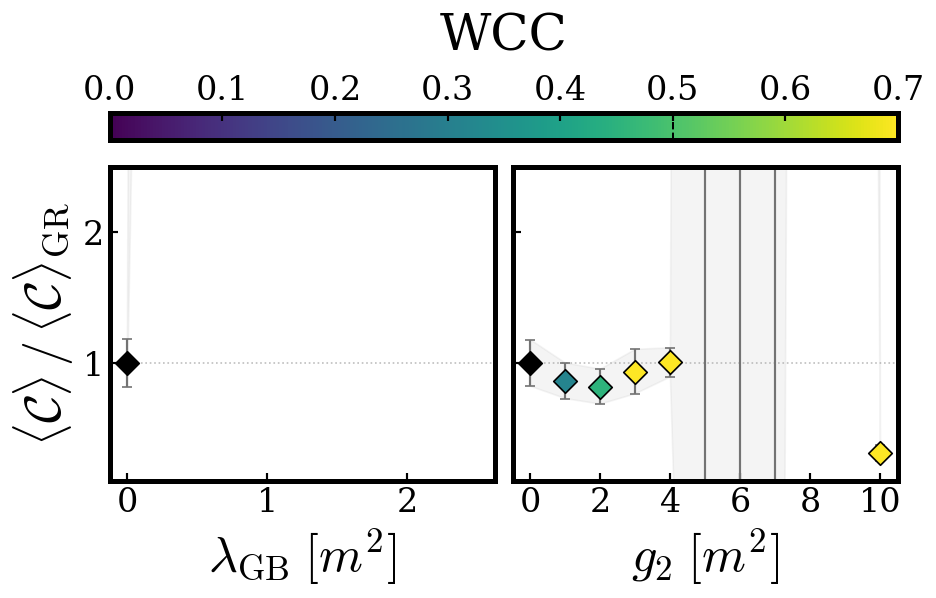


===== compactness: tot =====
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0 N_broad_peaks = 0
[EFT envelope] (1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.228705 N_broad_peaks = 1
[EFT envelope] (2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398734 N_broad_peaks = 1
[EFT envelope] (3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398187 N_broad_peaks = 1
[EFT envelope] (4.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.288366 N_broad_peaks = 1
[EFT envelope] (5.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 1.30323 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0 N_broad_peaks = 0
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 10.0) <W_EFT>_broad_peaks = 0.856175 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 12.0) <W_EFT>_broad_peaks = 1.01472 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 14.0) <W_EFT>_broad_peaks = 1.16919 N_broad_peaks = 1
[EFT

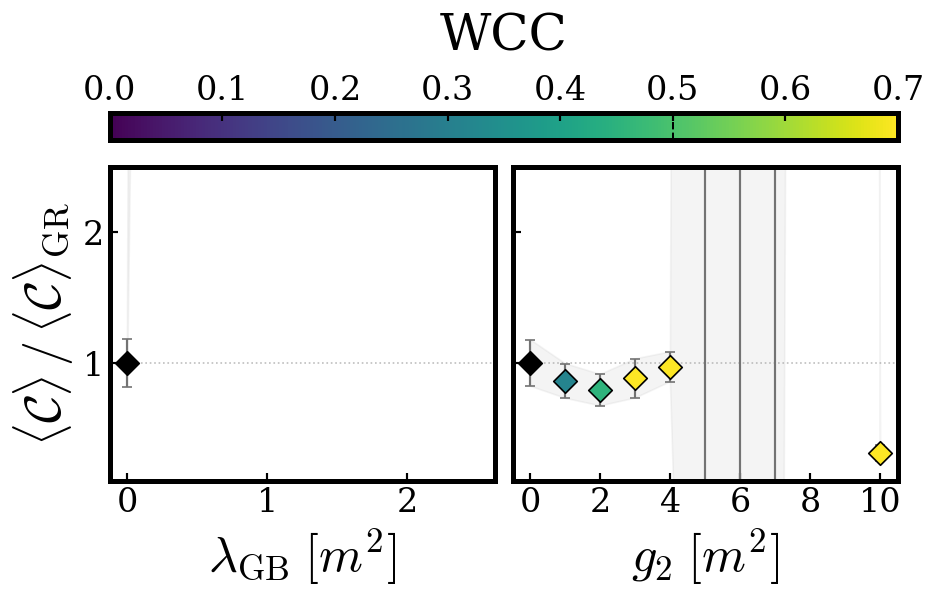


===== compactness: ms =====
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0 N_broad_peaks = 0
[EFT envelope] (1.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.228705 N_broad_peaks = 1
[EFT envelope] (2.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398734 N_broad_peaks = 1
[EFT envelope] (3.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.398187 N_broad_peaks = 1
[EFT envelope] (4.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0.288366 N_broad_peaks = 1
[EFT envelope] (5.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 1.30323 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 0.0) <W_EFT>_broad_peaks = 0 N_broad_peaks = 0
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 10.0) <W_EFT>_broad_peaks = 0.856175 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 12.0) <W_EFT>_broad_peaks = 1.01472 N_broad_peaks = 1
[EFT envelope] (0.0, 0.08, 0.0, -0.02, 3.0, 14.0) <W_EFT>_broad_peaks = 1.16919 N_broad_peaks = 1
[EFT 

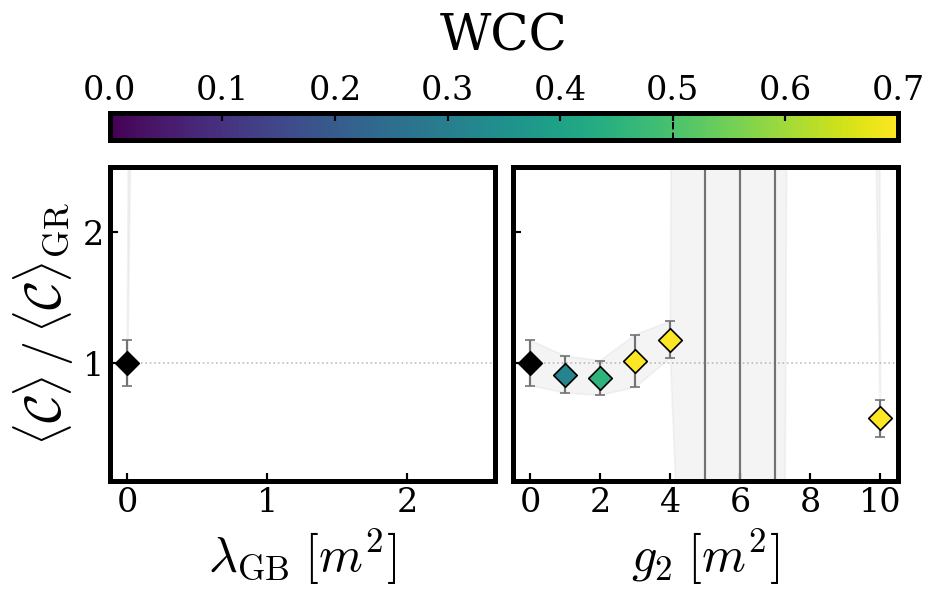

In [12]:
for MASS_DEF in ("phi", "tot", "ms"):
    print("\n===== compactness: " + MASS_DEF + " =====")
    from collections import defaultdict

    import os
    import numpy as np
    import matplotlib.pyplot as plt

    from scipy.signal import find_peaks
    from scipy.ndimage import gaussian_filter1d
    from matplotlib.colors import Normalize
    from matplotlib.cm import ScalarMappable
    from matplotlib.lines import Line2D


    # ============================================================
    # SETTINGS FOR THE EFT COLOUR CODING
    # ============================================================

    # Radial region used when taking max_r of the EFT diagnostic
    EFT_R_MAX = 100.0

    # False -> use eft_diagnostics.npz if it exists
    # True  -> recompute EFT diagnostics from solution.npy
    EFT_FORCE_RECOMPUTE = False

    # Linear colour scale
    EFT_COLOR_VMIN = 0.0
    EFT_COLOR_VMAX = 0.7

    # Colour map
    EFT_CMAP = plt.cm.viridis

    # Reference weak-coupling value
    EFT_THRESHOLD = 0.5


    # ============================================================
    # EFT ENVELOPE-PEAK SETTINGS
    # ============================================================

    # Gaussian smoothing scale measured directly in Delta ln(a).
    #
    # Larger value:
    #     removes more of the rapid oscillations
    #     and gives a smoother envelope.
    #
    # Smaller value:
    #     retains more small-scale structure.
    EFT_ENVELOPE_SMOOTH_SIGMA_LNA = 0.03


    # Minimum allowed separation between two BROAD envelope peaks,
    # again measured directly in Delta ln(a).
    #
    # Increasing this strongly suppresses the many small in-between peaks.
    EFT_ENVELOPE_MIN_SEPARATION_LNA = 0.10


    # Required prominence of an envelope peak as a fraction of the
    # full range of the smoothed diagnostic in the selected time window.
    #
    # e.g. 0.05 means a broad peak must have at least 5% prominence.
    EFT_ENVELOPE_PROMINENCE_REL = 0.05


    # Once a broad peak has been identified from the smoothed curve,
    # search this far to either side in the ORIGINAL diagnostic and
    # take the actual local maximum.
    #
    # This means the final average uses the real "high highs", not the
    # slightly reduced values of the smoothed curve.
    EFT_ENVELOPE_REFINE_HALF_WIDTH_LNA = 0.035


    # ============================================================
    # ORIGINAL COMPACTNESS PEAK STATISTICS
    #
    # Keep this unchanged for the compactness points/error bars.
    # ============================================================

    try:
        _peak_stats_last_window  # type: ignore[name-defined]

    except NameError:

        def _peak_stats_last_window(
            shifted_ln_a,
            C,
            dlna,
            prominence_rel=0.0,
            min_separation=1,
        ):

            sln = np.asarray(
                shifted_ln_a,
                dtype=float,
            )

            C = np.asarray(
                C,
                dtype=float,
            )

            n = min(
                len(sln),
                len(C),
            )

            sln = sln[:n]
            C = C[:n]

            finite = (
                np.isfinite(sln)
                & np.isfinite(C)
            )

            if not finite.any():
                return np.nan, np.nan, 0

            sln_f = sln[finite]
            C_f = C[finite]

            lna_max = sln_f.max()

            mask = (
                sln_f
                >= lna_max - dlna
            )

            if not mask.any():
                return np.nan, np.nan, 0

            C_win = C_f[mask]

            if C_win.size < 3:
                return (
                    float(C_win.max()),
                    0.0,
                    0,
                )

            kw = {}

            if min_separation > 1:

                kw["distance"] = int(
                    min_separation
                )

            if prominence_rel > 0.0:

                rng = float(
                    C_win.max()
                    - C_win.min()
                )

                if rng > 0:

                    kw["prominence"] = (
                        prominence_rel
                        * rng
                    )

            peak_idx, _ = find_peaks(
                C_win,
                **kw,
            )

            if peak_idx.size == 0:

                return (
                    float(C_win.max()),
                    0.0,
                    0,
                )

            peaks = C_win[
                peak_idx
            ]

            return (
                float(np.mean(peaks)),
                float(np.std(peaks)),
                int(peaks.size),
            )


    # ============================================================
    # BROAD EFT ENVELOPE PEAK STATISTICS
    # ============================================================

    def _eft_envelope_peak_stats_last_window(
        shifted_ln_a,
        W_eft,
        dlna,
    ):
        """
        Find only the BROAD peaks of the EFT diagnostic envelope.

        Procedure
        ---------
        1. Restrict to the last `dlna` interval.
        2. Smooth W_EFT as a function of ln(a).
        3. Detect well-separated peaks of the smoothed envelope.
        4. Around each envelope peak, return to the ORIGINAL W_EFT
           curve and find the actual local maximum.
        5. Average those original high values.

        Returns
        -------
        mean_peak : float
            Mean height of the broad-envelope peaks.

        std_peak : float
            Standard deviation of those peak heights.

        n_peaks : int
            Number of broad envelope peaks found.
        """

        x = np.asarray(
            shifted_ln_a,
            dtype=float,
        )

        y = np.asarray(
            W_eft,
            dtype=float,
        )

        # --------------------------------------------------------
        # Match lengths
        # --------------------------------------------------------

        n = min(
            len(x),
            len(y),
        )

        x = x[:n]
        y = y[:n]

        # --------------------------------------------------------
        # Remove NaNs / infinities
        # --------------------------------------------------------

        finite = (
            np.isfinite(x)
            & np.isfinite(y)
        )

        if not finite.any():

            return (
                np.nan,
                np.nan,
                0,
            )

        x = x[finite]
        y = y[finite]

        # --------------------------------------------------------
        # Sort in increasing ln(a), just to be safe
        # --------------------------------------------------------

        order = np.argsort(x)

        x = x[order]
        y = y[order]

        # --------------------------------------------------------
        # Restrict to the same final Delta ln(a) window
        # --------------------------------------------------------

        x_max = np.max(x)

        mask = (
            x
            >= x_max - dlna
        )

        x_win = x[mask]
        y_win = y[mask]

        if len(y_win) < 5:

            if len(y_win) == 0:
                return np.nan, np.nan, 0

            return (
                float(np.nanmax(y_win)),
                0.0,
                1,
            )

        # --------------------------------------------------------
        # Characteristic sampling interval in ln(a)
        # --------------------------------------------------------

        dx_array = np.diff(
            x_win
        )

        dx_array = dx_array[
            np.isfinite(dx_array)
            & (dx_array > 0)
        ]

        if dx_array.size == 0:

            return (
                float(np.nanmax(y_win)),
                0.0,
                1,
            )

        dx = float(
            np.median(dx_array)
        )

        # --------------------------------------------------------
        # Convert physical smoothing scale Delta ln(a)
        # into Gaussian sigma measured in samples
        # --------------------------------------------------------

        sigma_samples = (
            EFT_ENVELOPE_SMOOTH_SIGMA_LNA
            / dx
        )

        sigma_samples = max(
            sigma_samples,
            1.0,
        )

        # --------------------------------------------------------
        # Smooth away the rapid sub-oscillations
        # --------------------------------------------------------

        y_smooth = gaussian_filter1d(
            y_win,
            sigma=sigma_samples,
            mode="nearest",
        )

        # --------------------------------------------------------
        # Convert desired broad-peak separation from Delta ln(a)
        # into number of samples
        # --------------------------------------------------------

        distance_samples = int(
            round(
                EFT_ENVELOPE_MIN_SEPARATION_LNA
                / dx
            )
        )

        distance_samples = max(
            distance_samples,
            1,
        )

        # --------------------------------------------------------
        # Peak prominence from the range of the SMOOTHED envelope
        # --------------------------------------------------------

        smooth_range = float(
            np.nanmax(y_smooth)
            - np.nanmin(y_smooth)
        )

        peak_kwargs = {
            "distance": distance_samples,
        }

        if (
            EFT_ENVELOPE_PROMINENCE_REL > 0
            and smooth_range > 0
        ):

            peak_kwargs["prominence"] = (
                EFT_ENVELOPE_PROMINENCE_REL
                * smooth_range
            )

        # --------------------------------------------------------
        # Find BROAD peaks
        # --------------------------------------------------------

        broad_idx, properties = find_peaks(
            y_smooth,
            **peak_kwargs,
        )

        # --------------------------------------------------------
        # Fallback if no broad peak is found
        # --------------------------------------------------------

        if broad_idx.size == 0:

            i_max = int(
                np.nanargmax(
                    y_win
                )
            )

            return (
                float(y_win[i_max]),
                0.0,
                1,
            )

        # --------------------------------------------------------
        # IMPORTANT:
        #
        # We do NOT average y_smooth[broad_idx].
        #
        # Instead, for every broad envelope peak, we return to the
        # original unsmoothed diagnostic and locate the highest value
        # close to that broad peak.
        #
        # This gives the actual "high highs".
        # --------------------------------------------------------

        refined_peak_values = []

        refined_peak_positions = []

        for idx in broad_idx:

            x_peak = x_win[idx]

            local_mask = (
                np.abs(
                    x_win - x_peak
                )
                <= EFT_ENVELOPE_REFINE_HALF_WIDTH_LNA
            )

            if not local_mask.any():
                continue

            local_y = y_win[
                local_mask
            ]

            local_x = x_win[
                local_mask
            ]

            local_i = int(
                np.nanargmax(
                    local_y
                )
            )

            refined_peak_values.append(
                float(
                    local_y[local_i]
                )
            )

            refined_peak_positions.append(
                float(
                    local_x[local_i]
                )
            )

        refined_peak_values = np.asarray(
            refined_peak_values,
            dtype=float,
        )

        if refined_peak_values.size == 0:

            return (
                float(np.nanmax(y_win)),
                0.0,
                1,
            )

        return (
            float(
                np.mean(
                    refined_peak_values
                )
            ),
            float(
                np.std(
                    refined_peak_values
                )
            ),
            int(
                refined_peak_values.size
            ),
        )


    # ============================================================
    # COMPUTE / LOAD EFT DIAGNOSTICS
    # ============================================================

    def _ensure_eft_for_key(key):

        d = all_runs[key]

        if (
            "eft" in d
            and d["eft"] is not None
            and not EFT_FORCE_RECOMPUTE
        ):

            return d["eft"]

        run_dir = d[
            "run_dir"
        ]

        eft_path = os.path.join(
            run_dir,
            "eft_diagnostics.npz",
        )

        # --------------------------------------------------------
        # Load existing cache
        # --------------------------------------------------------

        if (
            os.path.exists(eft_path)
            and not EFT_FORCE_RECOMPUTE
        ):

            d["eft"] = dict(
                np.load(
                    eft_path,
                    allow_pickle=True,
                )
            )

            print(
                f"[EFT] loaded cache for {d['tag']}"
            )

            return d["eft"]

        # --------------------------------------------------------
        # Otherwise compute diagnostic
        # --------------------------------------------------------

        print(
            f"[EFT] computing diagnostic for {d['tag']}"
        )

        sol_i = np.load(
            os.path.join(
                run_dir,
                "solution.npy",
            )
        )

        matter_i = ScalarMatter(
            scalar_mu,
            d["mu"],
        )

        sv_i = StateVector(
            matter_i
        )

        spacing_i = CubicSpacing(
            **CubicSpacing.get_parameters(
                d["run_r_max"],
                d["run_min_dr"],
                d["run_max_dr"],
            )
        )

        grid_i = Grid(
            spacing_i,
            sv_i,
        )

        bg_i = FlatSphericalBackground(
            grid_i.r
        )

        (
            lgb_k,
            mu_k,
            beta_k,
            amp_k,
            width_k,
            g2_k,
        ) = key

        params = (
            lgb_k,
            a_mg,
            b_mg,
            chi0,
            d["coupling"],
            g2_k,
        )

        eft = get_eft_diagnostic(
            sol_i,
            d["t"],
            grid_i,
            bg_i,
            ScalarMatter(
                scalar_mu,
                d["mu"],
            ),
            params,
        )

        np.savez(
            eft_path,
            **eft,
        )

        d["eft"] = eft

        del sol_i

        print(
            f"[EFT] computed and cached for {d['tag']}"
        )

        return eft


    # ============================================================
    # BUILD W_EFT(t)
    # ============================================================

    def _eft_time_series(key):
        """
        Construct one EFT diagnostic time series.

        For each active coupling:

            W_GB(t) = max_r wc_lambda_bare

            W_g2(t) = max_r wc_g2_bare

        If both couplings are present:

            W_EFT(t) = max(W_GB, W_g2)
        """

        d = all_runs[key]

        (
            lgb,
            mu,
            beta,
            amp,
            width,
            g2,
        ) = key

        # --------------------------------------------------------
        # Pure GR
        # --------------------------------------------------------

        if (
            lgb == 0
            and g2 == 0
        ):

            ntime = len(
                d["shifted_ln_a"]
            )

            return np.zeros(
                ntime,
                dtype=float,
            )

        eft = _ensure_eft_for_key(
            key
        )

        if (
            eft is None
            or "r" not in eft
        ):

            return None

        r = np.asarray(
            eft["r"],
            dtype=float,
        )

        r_mask = (
            np.isfinite(r)
            & (r > 0)
            & (r <= EFT_R_MAX)
        )

        if not r_mask.any():

            return None

        active_diagnostics = []

        # --------------------------------------------------------
        # Gauss-Bonnet
        # --------------------------------------------------------

        if (
            lgb != 0
            and "wc_lambda_bare" in eft
        ):

            wc_lambda = np.asarray(
                eft[
                    "wc_lambda_bare"
                ],
                dtype=float,
            )

            wc_lambda_t = np.nanmax(
                wc_lambda[
                    :,
                    r_mask,
                ],
                axis=1,
            )

            active_diagnostics.append(
                wc_lambda_t
            )

        # --------------------------------------------------------
        # g2
        # --------------------------------------------------------

        if (
            g2 != 0
            and "wc_g2_bare" in eft
        ):

            wc_g2 = np.asarray(
                eft[
                    "wc_g2_bare"
                ],
                dtype=float,
            )

            wc_g2_t = np.nanmax(
                wc_g2[
                    :,
                    r_mask,
                ],
                axis=1,
            )

            active_diagnostics.append(
                wc_g2_t
            )

        if (
            len(active_diagnostics)
            == 0
        ):

            return None

        n = min(
            len(arr)
            for arr
            in active_diagnostics
        )

        active_diagnostics = [
            arr[:n]
            for arr
            in active_diagnostics
        ]

        if (
            len(active_diagnostics)
            == 1
        ):

            W_eft = (
                active_diagnostics[0]
            )

        else:

            W_eft = np.nanmax(
                np.vstack(
                    active_diagnostics
                ),
                axis=0,
            )

        return W_eft


    # ============================================================
    # ONE EFT NUMBER PER RUN
    #
    # THIS NOW USES BROAD ENVELOPE PEAKS
    # ============================================================

    def _eft_peak_mean_for_key(
        key,
        dlna,
    ):

        (
            lgb,
            mu,
            beta,
            amp,
            width,
            g2,
        ) = key

        # GR diagnostic = 0
        if (
            lgb == 0
            and g2 == 0
        ):

            return (
                0.0,
                0.0,
                0,
            )

        d = all_runs[key]

        W_eft = _eft_time_series(
            key
        )

        if W_eft is None:

            return (
                np.nan,
                np.nan,
                0,
            )

        shifted_ln_a = np.asarray(
            d["shifted_ln_a"],
            dtype=float,
        )

        n = min(
            len(shifted_ln_a),
            len(W_eft),
        )

        shifted_ln_a = (
            shifted_ln_a[:n]
        )

        W_eft = np.asarray(
            W_eft[:n],
            dtype=float,
        )

        # --------------------------------------------------------
        # BROAD ENVELOPE PEAK STATISTICS
        # --------------------------------------------------------

        return _eft_envelope_peak_stats_last_window(
            shifted_ln_a,
            W_eft,
            dlna,
        )


    # ============================================================
    # GR COMPACTNESS BASELINE
    # ============================================================

    def _C_GR_for(
        P_MU,
        P_BETA,
        P_AMP,
        P_WIDTH,
        P_DLNA,
    ):

        for k in all_runs:

            (
                lgb_,
                mu_,
                beta_,
                amp_,
                width_,
                g2_,
            ) = k

            if (
                lgb_ != 0
                or g2_ != 0
            ):

                continue

            if (
                mu_ == P_MU
                and beta_ == P_BETA
                and amp_ == P_AMP
                and width_ == P_WIDTH
            ):

                d = all_runs[k]

                Cm, _, _ = (
                    _peak_stats_last_window(
                        d[
                            "shifted_ln_a"
                        ],
                        _mass_series(d, "C"),
                        P_DLNA,
                    )
                )

                return (
                    float(Cm)
                    if (
                        np.isfinite(Cm)
                        and Cm > 0
                    )
                    else np.nan
                )

        return np.nan


    # ============================================================
    # COLLECT COMPACTNESS + EFT INFORMATION
    # ============================================================

    def _collect_points(
        groups,
        dlna,
        key_index,
    ):

        out = {}

        for grp_val, keys in groups.items():

            pts = []

            for key in keys:

                d = all_runs[key]

                # ------------------------------------------------
                # Compactness
                # ------------------------------------------------

                Cm, Ce, nC = (
                    _peak_stats_last_window(
                        d[
                            "shifted_ln_a"
                        ],
                        _mass_series(d, "C"),
                        dlna,
                    )
                )

                if not np.isfinite(Cm):
                    continue

                # ------------------------------------------------
                # BROAD EFT ENVELOPE PEAKS
                # ------------------------------------------------

                Em, Ee, nE = (
                    _eft_peak_mean_for_key(
                        key,
                        dlna,
                    )
                )

                pts.append(
                    (
                        key[
                            key_index
                        ],
                        Cm,
                        Ce,
                        Em,
                        Ee,
                        key,
                    )
                )

                print(
                    "[EFT envelope]",
                    key,
                    f"<W_EFT>_broad_peaks = {Em:.6g}",
                    f"N_broad_peaks = {nE}",
                )

            if pts:

                out[grp_val] = sorted(
                    pts,
                    key=lambda p: p[0],
                )

        return out


    # ============================================================
    # MARKER SHAPES
    # ============================================================

    _markers_lgb_d = [
        "D",
        "s",
        "D",
        "^",
        "v",
        "<",
        ">",
        "P",
        "X",
    ]

    _markers_g2_d = [
        "D",
        "s",
        "D",
        "^",
        "v",
        "<",
        ">",
        "P",
        "X",
    ]


    # ============================================================
    # LINEAR COLOUR NORMALISATION
    # ============================================================

    eft_norm = Normalize(
        vmin=EFT_COLOR_VMIN,
        vmax=EFT_COLOR_VMAX,
        clip=True,
    )


    def _eft_marker_colour(
        value,
    ):

        if not np.isfinite(
            value
        ):

            return "lightgrey"

        if value <= 0:

            return "black"

        return EFT_CMAP(
            eft_norm(
                value
            )
        )


    # ============================================================
    # CREATE FIGURE
    # ============================================================

    fig, (
        ax_l,
        ax_r,
    ) = plt.subplots(
        1,
        2,
        figsize=(8, 5),
        sharey=True,
    )

    for ax in (ax_l, ax_r):
        ax.axhline(
            1.0,
            color="0.75",
            ls=":",
            lw=1.0,
            zorder=0,
        )


    # ============================================================
    # GR BASELINES
    # ============================================================

    C_GR_left = _C_GR_for(
        P4C_MU,
        P4C_BETA,
        P4C_AMP,
        P4C_WIDTH,
        P4C_DLNA,
    )

    C_GR_right = _C_GR_for(
        P4B_MU,
        P4B_BETA,
        P4B_AMP,
        P4B_WIDTH,
        P4B_DLNA,
    )

    if not np.isfinite(
        C_GR_left
    ):

        print(
            "[warn] no GR run found for P4C cut; "
            "left panel falls back to C_GR = 1."
        )

        C_GR_left = 1.0


    if not np.isfinite(
        C_GR_right
    ):

        print(
            "[warn] no GR run found for P4B cut; "
            "right panel falls back to C_GR = 1."
        )

        C_GR_right = 1.0


    # ============================================================
    # LEFT PANEL
    #
    # C/C_GR vs lambda_GB/2
    # ============================================================

    g2_groups = defaultdict(
        list
    )

    for key in all_runs:

        (
            lgb,
            mu,
            beta,
            amp,
            width,
            g2,
        ) = key

        if (
            mu != P4C_MU
            or beta != P4C_BETA
            or amp != P4C_AMP
            or width != P4C_WIDTH
        ):

            continue

        if (
            g2 not in P4C_G2_SHOW
            or lgb not in P4C_LGB_SHOW
        ):

            continue

        g2_groups[
            g2
        ].append(
            key
        )


    g2_points = _collect_points(
        g2_groups,
        P4C_DLNA,
        key_index=0,
    )


    for idx, g2_val in enumerate(
        sorted(
            g2_points.keys()
        )
    ):

        pts = g2_points[
            g2_val
        ]

        marker = _markers_g2_d[
            idx
            % len(
                _markers_g2_d
            )
        ]

        x = np.array(
            [
                p[0]
                for p
                in pts
            ],
            dtype=float,
        ) / 2.0

        y = np.array(
            [
                p[1]
                for p
                in pts
            ],
            dtype=float,
        ) / C_GR_left

        ye = np.array(
            [
                p[2]
                for p
                in pts
            ],
            dtype=float,
        ) / C_GR_left

        eft_values = np.array(
            [
                p[3]
                for p
                in pts
            ],
            dtype=float,
        )

        # --------------------------------------------------------
        # Uncertainty band
        # --------------------------------------------------------

        ax_l.fill_between(
            x,
            y - ye,
            y + ye,
            color="0.65",
            alpha=0.12,
            zorder=1,
        )

        # --------------------------------------------------------
        # Error bars
        # --------------------------------------------------------

        ax_l.errorbar(
            x,
            y,
            yerr=ye,
            fmt="none",
            ecolor="0.45",
            capsize=3,
            capthick=1.0,
            elinewidth=1.3,
            zorder=3,
        )

        # --------------------------------------------------------
        # EFT-coloured markers
        # --------------------------------------------------------

        for (
            xi,
            yi,
            eft_val,
        ) in zip(
            x,
            y,
            eft_values,
        ):

            ax_l.scatter(
                xi,
                yi,
                s=100,
                marker=marker,
                facecolor=(
                    _eft_marker_colour(
                        eft_val
                    )
                ),
                edgecolor="black",
                linewidth=1.0,
                zorder=5,
            )


    left_legend_handle = Line2D(
        [0],
        [0],
        marker=(
            _markers_g2_d[0]
        ),
        linestyle="none",
        markerfacecolor="0.7",
        markeredgecolor="black",
        markersize=8,
        label=(
            r"$\lambda_{\rm GB}$"
        ),
    )

    ax_l.set_xlim(
        -0.125,
        2.625,
    )

    ax_l.set_xticks(
        np.arange(
            0.0,
            3.0,
            1,
        )
    )

    ax_l.set_xlabel(
        r"$\lambda_{\rm GB}\;[m^2]$", fontsize=30
    )

    ax_l.set_ylabel(
        r"$\langle\mathcal{C}\rangle"
        r"\,/\,"
        r"\langle\mathcal{C}\rangle_{\rm GR}$", fontsize=30
    )

    ax_l.set_ylim(
        0.1,
        2.5,
    )

    ax_l.tick_params(
        which="both",
        top=False,
        right=False,
        labelsize=20,
    )

    '''ax_l.legend(
        handles=[
            left_legend_handle
        ],
        loc="best",
        frameon=False,
        fontsize=20,
    )'''


    # ============================================================
    # RIGHT PANEL
    #
    # C/C_GR vs g2/2
    # ============================================================

    lgb_groups = defaultdict(
        list
    )

    for key in all_runs:

        (
            lgb,
            mu,
            beta,
            amp,
            width,
            g2,
        ) = key

        if (
            mu != P4B_MU
            or beta != P4B_BETA
            or amp != P4B_AMP
            or width != P4B_WIDTH
        ):

            continue

        if (
            lgb not in P4B_LGB_SHOW
            or g2 not in P4B_G2_SHOW
        ):

            continue

        lgb_groups[
            lgb
        ].append(
            key
        )


    lgb_points = _collect_points(
        lgb_groups,
        P4B_DLNA,
        key_index=5,
    )


    for idx, lgb_val in enumerate(
        sorted(
            lgb_points.keys()
        )
    ):

        pts = lgb_points[
            lgb_val
        ]

        marker = _markers_lgb_d[
            idx
            % len(
                _markers_lgb_d
            )
        ]

        x = np.array(
            [
                p[0]
                for p
                in pts
            ],
            dtype=float,
        ) / 2.0

        y = np.array(
            [
                p[1]
                for p
                in pts
            ],
            dtype=float,
        ) / C_GR_right

        ye = np.array(
            [
                p[2]
                for p
                in pts
            ],
            dtype=float,
        ) / C_GR_right

        eft_values = np.array(
            [
                p[3]
                for p
                in pts
            ],
            dtype=float,
        )

        # --------------------------------------------------------
        # Uncertainty band
        # --------------------------------------------------------

        ax_r.fill_between(
            x,
            y - ye,
            y + ye,
            color="0.65",
            alpha=0.12,
            zorder=1,
        )

        # --------------------------------------------------------
        # Error bars
        # --------------------------------------------------------

        ax_r.errorbar(
            x,
            y,
            yerr=ye,
            fmt="none",
            ecolor="0.45",
            capsize=3,
            capthick=1.0,
            elinewidth=1.3,
            zorder=3,
        )

        # --------------------------------------------------------
        # EFT-coloured markers
        # --------------------------------------------------------

        for (
            xi,
            yi,
            eft_val,
        ) in zip(
            x,
            y,
            eft_values,
        ):

            ax_r.scatter(
                xi,
                yi,
                s=100,
                marker=marker,
                facecolor=(
                    _eft_marker_colour(
                        eft_val
                    )
                ),
                edgecolor="black",
                linewidth=1.0,
                zorder=5,
            )


    right_legend_handle = Line2D(
        [0],
        [0],
        marker=(
            _markers_lgb_d[0]
        ),
        linestyle="none",
        markerfacecolor="0.7",
        markeredgecolor="black",
        markersize=8,
        label=r"$g_2$",
    )


    ax_r.set_xlim(
        -0.5,
        10.5,
    )

    ax_r.set_xticks(
        np.arange(
            0,
            11,
            2,
        )
    )

    ax_r.set_frame_on(
        True
    )

    for spine in (
        ax_r.spines.values()
    ):

        spine.set_zorder(
            10
        )

    ax_r.set_xlabel(
        r"$g_2\;[m^2]$", fontsize=30
    )

    ax_r.tick_params(
        which="both",
        top=False,
        right=False,
        labelsize=20,
    )

    '''ax_r.legend(
        handles=[
            right_legend_handle
        ],
        loc="best",
        frameon=False,
        fontsize=15,
    )'''


    # ============================================================
    # LAYOUT
    #
    # Leave room on the TOP for the horizontal colourbar.
    # ============================================================

    fig.tight_layout(
        rect=[
            0.0,
            0.0,
            1.0,
            0.78,
        ]
    )


    # ============================================================
    # EFT COLOURBAR
    #
    # Horizontal, above both panels.
    #
    # Left edge aligned with the left panel.
    # Right edge aligned with the right panel.
    # ============================================================

    pos_l = ax_l.get_position()
    pos_r = ax_r.get_position()

    cbar_gap = 0.045
    cbar_height = 0.045

    cax = fig.add_axes(
        [
            pos_l.x0,
            pos_l.y1 + cbar_gap,
            pos_r.x1 - pos_l.x0,
            cbar_height,
        ]
    )


    sm = ScalarMappable(
        norm=eft_norm,
        cmap=EFT_CMAP,
    )

    sm.set_array(
        []
    )

    cbar = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
    )

    cbar.ax.xaxis.set_ticks_position(
        "top"
    )

    cbar.ax.xaxis.set_label_position(
        "top"
    )

    cbar.set_label(
        r"WCC",
        fontsize=30,
        labelpad=15,
    )

    cbar.ax.tick_params(
        labelsize=20,
    )


    # ============================================================
    # EFT THRESHOLD ON COLOURBAR
    # ============================================================

    if (
        EFT_COLOR_VMIN
        <= EFT_THRESHOLD
        <= EFT_COLOR_VMAX
    ):

        cbar.ax.axvline(
            EFT_THRESHOLD,
            color="black",
            linestyle="--",
            linewidth=1.2,
        )


    # ============================================================
    # SAVE
    # ============================================================

    save_fig(
        fig,
        "compactness_vs_lgb_and_g2_normalized_EFT_coloured_M" + MASS_DEF,
    )

    plt.show()


## Compactness difference, $\rho_\phi$ minus $\rho_{\rm tot}$

Same couplings and peak window as the figure above. The $y$ value is the difference of the two normalised compactness points,

$$\frac{\langle\mathcal{C}\rangle_{\phi}}{\langle\mathcal{C}\rangle_{\rm GR}}-\frac{\langle\mathcal{C}\rangle_{\rm tot}}{\langle\mathcal{C}\rangle_{\rm GR}}.$$

Each ratio uses that definition's own GR baseline, so this is the vertical gap between the $\phi$ and tot versions of the plot above. Zero means the two mass definitions agree.


<>:133: SyntaxWarning: invalid escape sequence '\l'
<>:133: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_2287500/497127660.py:133: SyntaxWarning: invalid escape sequence '\l'
  '''ax_l.legend(


  saved compactness_phi_minus_tot_vs_lgb_and_g2_EFT_coloured.pdf and compactness_phi_minus_tot_vs_lgb_and_g2_EFT_coloured.png


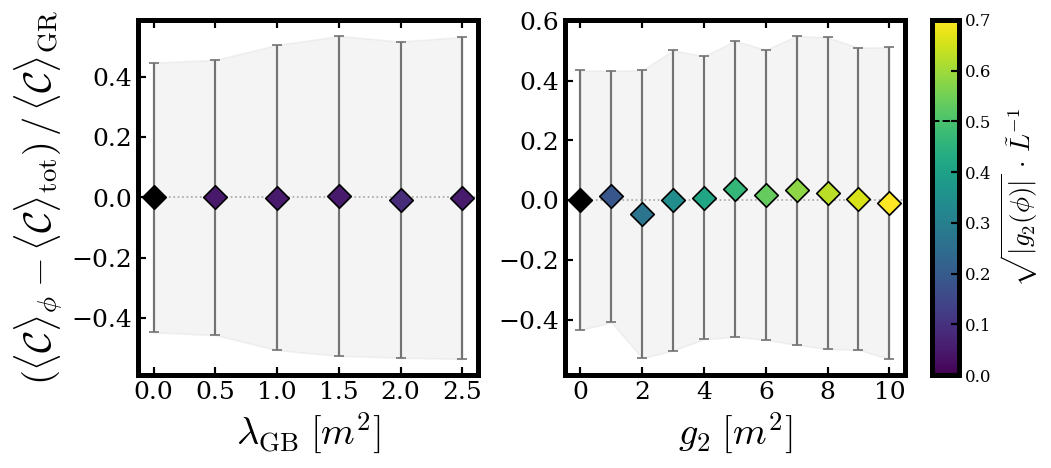

In [13]:
from collections import defaultdict
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# Difference of the normalised compactness points in the figure above:
# y = C_phi / C_GR,phi - C_tot / C_GR,tot.
# Same selection, peak window, markers and EFT colours.

for _name in (
    "_peak_stats_last_window",
    "_eft_peak_mean_for_key",
    "_eft_marker_colour",
    "_markers_g2_d",
    "_markers_lgb_d",
    "eft_norm",
    "EFT_CMAP",
    "EFT_THRESHOLD",
    "EFT_COLOR_VMIN",
    "EFT_COLOR_VMAX",
):
    if _name not in globals():
        raise RuntimeError(
            f"{_name} is not defined. Run the EFT-coloured compactness cell before this one."
        )


def _gr_peak_C(which, mu, beta, amp, width, dlna):
    """Peak-mean compactness of the GR run for one mass definition."""
    for key, d in all_runs.items():
        lgb, mu_, beta_, amp_, width_, g2 = key
        if lgb != 0 or g2 != 0:
            continue
        if mu_ == mu and beta_ == beta and amp_ == amp and width_ == width:
            series = d["osc"]["C"] if which == "phi" else d["massdefs"]["C_tot"]
            ym, _, _ = _peak_stats_last_window(d["shifted_ln_a"], np.asarray(series), dlna)
            return float(ym) if np.isfinite(ym) and ym > 0 else np.nan
    return np.nan


def _collect_c_diff(groups, dlna, key_index, cgr_phi, cgr_tot):
    """(x, y_phi-y_tot, combined std, WCC) per group."""
    out = {}
    for grp_val, keys in groups.items():
        pts = []
        for key in keys:
            d = all_runs[key]
            pm, pe, _ = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["osc"]["C"]), dlna)
            tm, te, _ = _peak_stats_last_window(
                d["shifted_ln_a"], np.asarray(d["massdefs"]["C_tot"]), dlna)
            if not (np.isfinite(pm) and np.isfinite(tm)):
                continue
            y = pm / cgr_phi - tm / cgr_tot
            ye = float(np.hypot(pe / cgr_phi, te / cgr_tot))
            em, _, _ = _eft_peak_mean_for_key(key, dlna)
            pts.append((key[key_index], y, ye, float(em)))
        if pts:
            out[grp_val] = sorted(pts, key=lambda p: p[0])
    return out


def _plot_c_diff(ax, points, markers, x_div=1.0):
    for idx, grp_val in enumerate(sorted(points.keys())):
        pts = points[grp_val]
        marker = markers[idx % len(markers)]
        x = np.array([p[0] for p in pts], dtype=float) / x_div
        y = np.array([p[1] for p in pts], dtype=float)
        ye = np.array([p[2] for p in pts], dtype=float)
        wcc = np.array([p[3] for p in pts], dtype=float)
        ax.fill_between(x, y - ye, y + ye, color="0.65", alpha=0.12, zorder=1)
        ax.errorbar(
            x, y, yerr=ye, fmt="none", ecolor="0.45",
            capsize=3, capthick=1.0, elinewidth=1.3, zorder=3,
        )
        for xi, yi, ev in zip(x, y, wcc):
            ax.scatter(
                xi, yi, s=100, marker=marker,
                facecolor=_eft_marker_colour(ev),
                edgecolor="black", linewidth=1.0, zorder=5,
            )
    ax.axhline(0.0, color="grey", ls=":", lw=1.0, alpha=0.7, zorder=0)


Cdiff_GR_phi_left = _gr_peak_C("phi", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
Cdiff_GR_tot_left = _gr_peak_C("tot", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
Cdiff_GR_phi_right = _gr_peak_C("phi", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
Cdiff_GR_tot_right = _gr_peak_C("tot", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
for _nm, _val in (
    ("Cdiff_GR_phi_left", Cdiff_GR_phi_left),
    ("Cdiff_GR_tot_left", Cdiff_GR_tot_left),
    ("Cdiff_GR_phi_right", Cdiff_GR_phi_right),
    ("Cdiff_GR_tot_right", Cdiff_GR_tot_right),
):
    if not np.isfinite(_val):
        raise RuntimeError(f"no GR compactness baseline for {_nm}")

g2_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
        continue
    if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
        continue
    g2_groups[g2].append(key)

lgb_groups = defaultdict(list)
for key in all_runs:
    lgb, mu, beta, amp, width, g2 = key
    if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
        continue
    if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
        continue
    lgb_groups[lgb].append(key)

left_pts = _collect_c_diff(g2_groups, P4C_DLNA, 0, Cdiff_GR_phi_left, Cdiff_GR_tot_left)
right_pts = _collect_c_diff(lgb_groups, P4B_DLNA, 5, Cdiff_GR_phi_right, Cdiff_GR_tot_right)

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(9, 4), sharey=False)
_plot_c_diff(ax_l, left_pts, _markers_g2_d, x_div=2.0)
_plot_c_diff(ax_r, right_pts, _markers_lgb_d, x_div=2.0)

ax_l.set_xlim(-0.125, 2.625)
ax_l.set_xticks(np.arange(0.0, 3.0, 0.5))
ax_r.set_xlim(-0.5, 10.5)
ax_r.set_xticks(np.arange(0, 11, 2))

ax_l.set_xlabel(r"$\lambda_{\rm GB}\;[m^2]$")
ax_r.set_xlabel(r"$g_2\;[m^2]$")
ax_l.set_ylabel(
    r"$(\langle\mathcal{C}\rangle_{\phi}-\langle\mathcal{C}\rangle_{\rm tot})"
    r"\,/\,\langle\mathcal{C}\rangle_{\rm GR}$"
)
'''ax_l.legend(
    handles=[Line2D(
        [0], [0], marker=_markers_g2_d[0], linestyle="none",
        markerfacecolor="0.7", markeredgecolor="black", markersize=8,
        label=r"$\lambda_{\rm GB}$",
    )],
    loc="best", frameon=False,
)
ax_r.legend(
    handles=[Line2D(
        [0], [0], marker=_markers_lgb_d[0], linestyle="none",
        markerfacecolor="0.7", markeredgecolor="black", markersize=8,
        label=r"$g_2$",
    )],
    loc="best", frameon=False,
)'''
for ax in (ax_l, ax_r):
    ax.tick_params(which="both", top=True, right=False)

fig.tight_layout(rect=[0.0, 0.0, 0.86, 1.0])
pos_r = ax_r.get_position()
cax = fig.add_axes([pos_r.x1 + 0.025, pos_r.y0, 0.025, pos_r.height])
sm = ScalarMappable(norm=eft_norm, cmap=EFT_CMAP)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax, orientation="vertical")
cbar.set_label(r"$\sqrt{|g_2(\phi)|}\,\cdot\,\tilde L^{-1}$", fontsize=16)
cbar.ax.tick_params(labelsize=10)
if EFT_COLOR_VMIN <= EFT_THRESHOLD <= EFT_COLOR_VMAX:
    cbar.ax.axhline(EFT_THRESHOLD, color="black", linestyle="--", linewidth=1.2)

save_fig(fig, "compactness_phi_minus_tot_vs_lgb_and_g2_EFT_coloured")
plt.show()


## Radius and mass vs GR, EFT-coloured

Positive `P4C` / `P4B` couplings. Ratios use that definition's own GR baseline. For **ms**, the radius series is the phi radius, so the radius panels match **phi**.


===== radius and mass: phi =====
  saved radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mphi.pdf and radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mphi.png


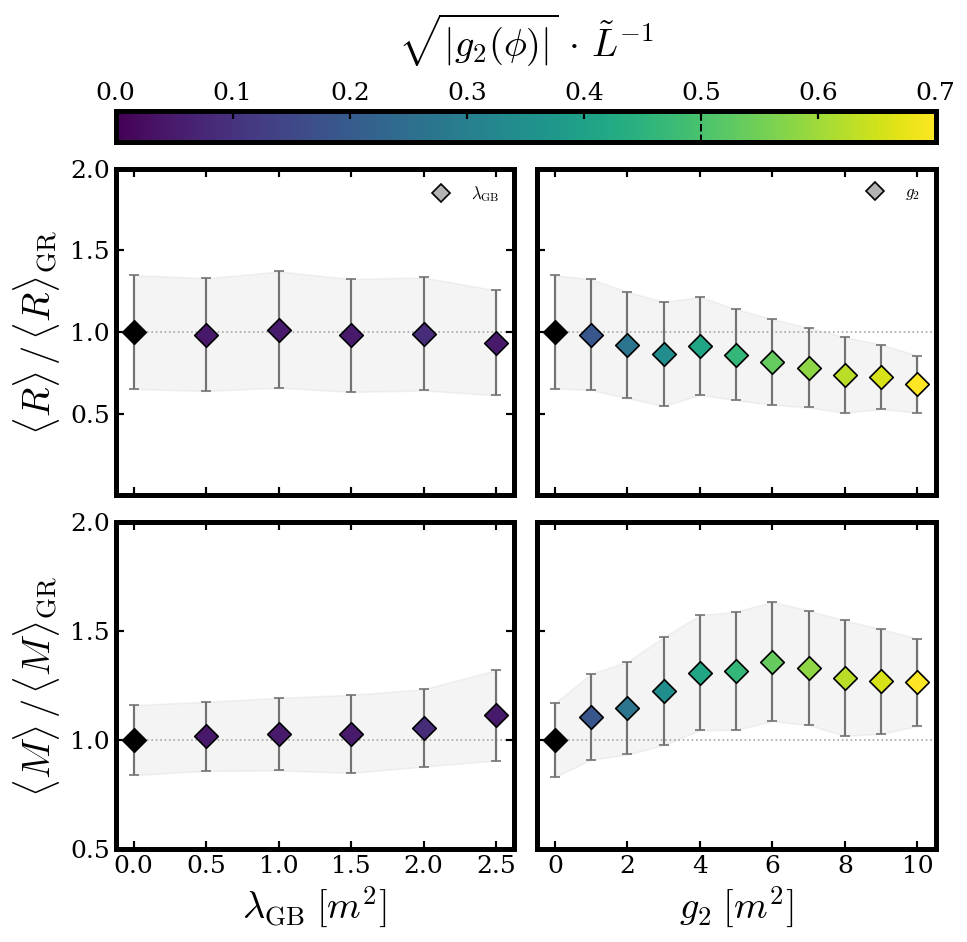


===== radius and mass: tot =====
  saved radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mtot.pdf and radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mtot.png


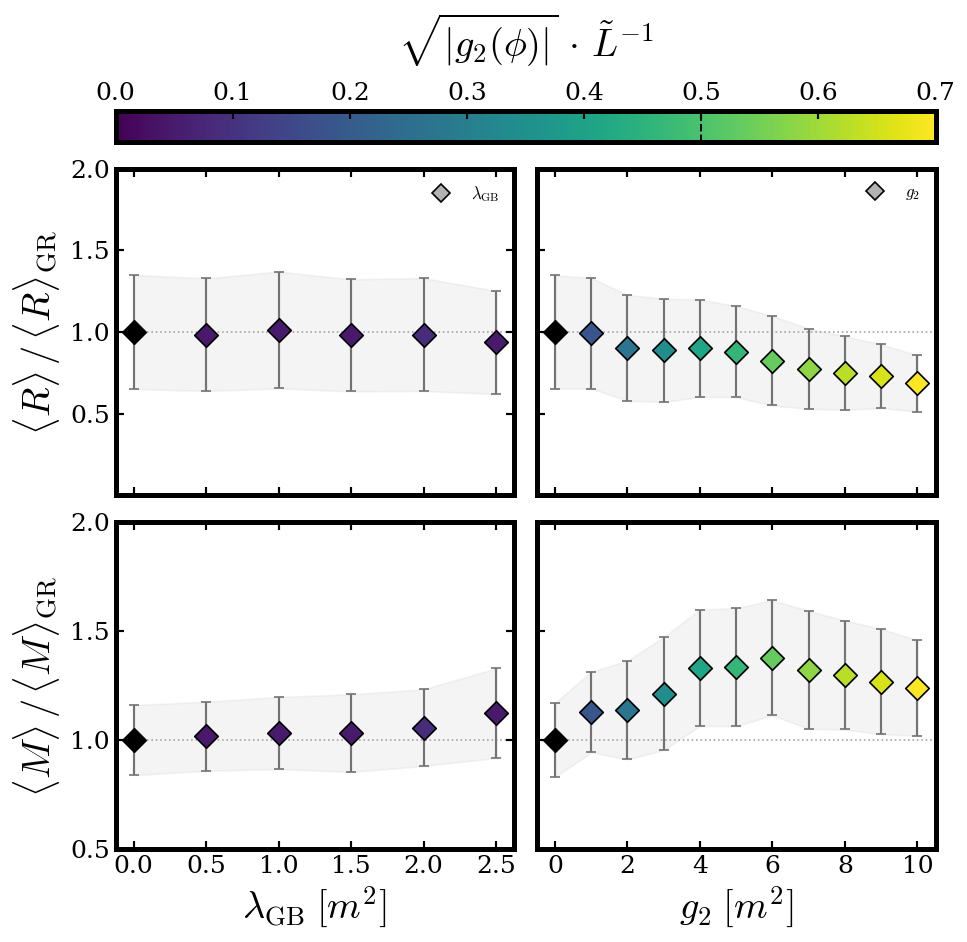


===== radius and mass: ms =====
  saved radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mms.pdf and radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_Mms.png


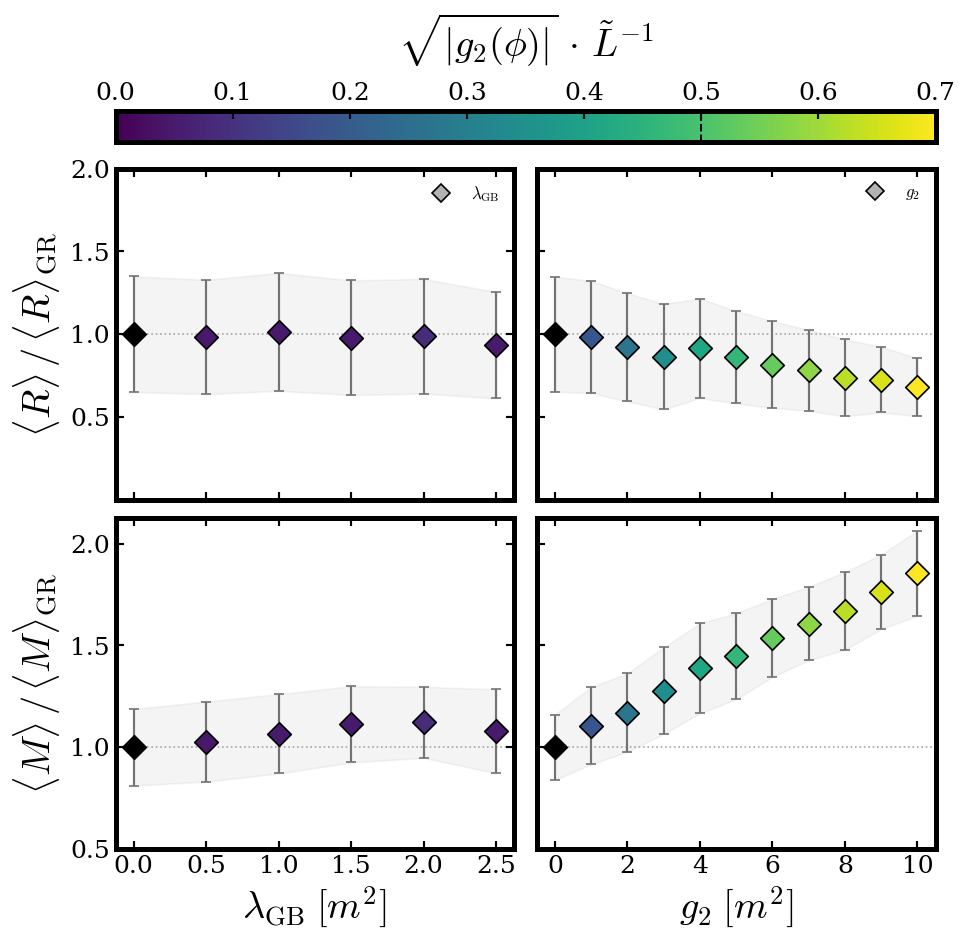

In [14]:
for MASS_DEF in ("phi", "tot", "ms"):
    print("\n===== radius and mass: " + MASS_DEF + " =====")
    # Panel 4d-R/M vs GR, EFT-coloured — same quantities as the ratio plot above
    # (left: vs lambda_GB/2, P4C selection; right: vs g2/2, P4B selection;
    # top: radius peaks; bottom: mass peaks), drawn with the money-plot style:
    # grey uncertainty bands, grey error bars, and markers coloured by the same
    # weak-coupling envelope peak used for compactness. A given (lambda_GB, g2)
    # run therefore has the same colour here as on the compactness figure.
    # The colourbar is horizontal and sits above both columns,
    # from the left edge of the left panels to the right edge of the right panels.

    from collections import defaultdict
    from matplotlib.colors import Normalize
    from matplotlib.cm import ScalarMappable

    for _name in (
        "_peak_stats_last_window",
        "_eft_peak_mean_for_key",
        "_eft_marker_colour",
        "eft_norm",
        "EFT_CMAP",
        "EFT_THRESHOLD",
        "EFT_COLOR_VMIN",
        "EFT_COLOR_VMAX",
    ):
        if _name not in globals():
            raise RuntimeError(
                f"{_name} is not defined. Run the EFT-coloured compactness "
                "cell before this one."
            )

    # Same marker cycle as the compactness money plot.
    _markers_g2_eft = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]
    _markers_lgb_eft = ["D", "s", "D", "^", "v", "<", ">", "P", "X"]

    _eft_colour_cache = {}


    def _wcc_for_key(key, dlna):
        """Weak-coupling envelope peak, identical to the compactness money plot."""
        cached = _eft_colour_cache.get((key, dlna))
        if cached is None:
            Em, _, _ = _eft_peak_mean_for_key(key, dlna)
            cached = float(Em)
            _eft_colour_cache[(key, dlna)] = cached
        return cached


    def _collect_qty_wcc(groups, dlna, key_index, qty):
        """Sorted (x, peak_mean, peak_std, WCC) per group."""
        out = {}
        for grp_val, keys in groups.items():
            pts = []
            for key in keys:
                d = all_runs[key]
                ym, ye, _ = _peak_stats_last_window(
                    d["shifted_ln_a"], _mass_series(d, qty), dlna)
                if not np.isfinite(ym):
                    continue
                pts.append((key[key_index], ym, ye, _wcc_for_key(key, dlna)))
            if pts:
                out[grp_val] = sorted(pts, key=lambda p: p[0])
        return out


    def _plot_wcc_ratio(ax, points, markers, y_GR, x_div=1.0):
        """Money-plot markers and error bars, y divided by the GR baseline."""
        for idx, grp_val in enumerate(sorted(points.keys())):
            pts = points[grp_val]
            marker = markers[idx % len(markers)]
            x = np.array([p[0] for p in pts], dtype=float) / x_div
            y = np.array([p[1] for p in pts], dtype=float) / y_GR
            ye = np.array([p[2] for p in pts], dtype=float) / y_GR
            wcc = np.array([p[3] for p in pts], dtype=float)

            ax.fill_between(x, y - ye, y + ye, color="0.65", alpha=0.12, zorder=1)
            ax.errorbar(
                x, y, yerr=ye, fmt="none", ecolor="0.45",
                capsize=3, capthick=1.0, elinewidth=1.3, zorder=3,
            )
            for xi, yi, ev in zip(x, y, wcc):
                ax.scatter(
                    xi, yi, s=100, marker=marker,
                    facecolor=_eft_marker_colour(ev),
                    edgecolor="black", linewidth=1.0, zorder=5,
                )
        ax.axhline(1.0, color="grey", ls=":", lw=1.0, alpha=0.7, zorder=0)


    # Same run grouping and GR baselines as the ratio plot above.

    def _gr_peak_for_massdef(qty, mu, beta, amp, width, dlna):
        """Peak-mean of qty for the GR run, using the active mass definition."""
        for k in all_runs:
            lgb_, mu_, beta_, amp_, width_, g2_ = k
            if lgb_ != 0 or g2_ != 0:
                continue
            if (mu_ == mu and beta_ == beta and amp_ == amp and width_ == width):
                d = all_runs[k]
                ym, _, _ = _peak_stats_last_window(
                    d["shifted_ln_a"], _mass_series(d, qty), dlna)
                return float(ym) if np.isfinite(ym) and ym > 0 else np.nan
        return np.nan

    R_GR_left = _gr_peak_for_massdef("R", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
    R_GR_right = _gr_peak_for_massdef("R", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
    M_GR_left = _gr_peak_for_massdef("M", P4C_MU, P4C_BETA, P4C_AMP, P4C_WIDTH, P4C_DLNA)
    M_GR_right = _gr_peak_for_massdef("M", P4B_MU, P4B_BETA, P4B_AMP, P4B_WIDTH, P4B_DLNA)
    for _nm, _val in (
        ("R_GR_left", R_GR_left),
        ("R_GR_right", R_GR_right),
        ("M_GR_left", M_GR_left),
        ("M_GR_right", M_GR_right),
    ):
        if not np.isfinite(_val):
            print(f"[warn] no GR run found for {_nm} ({MASS_DEF}); falling back to 1.")
            if _nm == "R_GR_left":
                R_GR_left = 1.0
            elif _nm == "R_GR_right":
                R_GR_right = 1.0
            elif _nm == "M_GR_left":
                M_GR_left = 1.0
            else:
                M_GR_right = 1.0

    g2_groups = defaultdict(list)
    for key in all_runs:
        lgb, mu, beta, amp, width, g2 = key
        if mu != P4C_MU or beta != P4C_BETA or amp != P4C_AMP or width != P4C_WIDTH:
            continue
        if g2 not in P4C_G2_SHOW or lgb not in P4C_LGB_SHOW:
            continue
        g2_groups[g2].append(key)

    lgb_groups = defaultdict(list)
    for key in all_runs:
        lgb, mu, beta, amp, width, g2 = key
        if mu != P4B_MU or beta != P4B_BETA or amp != P4B_AMP or width != P4B_WIDTH:
            continue
        if lgb not in P4B_LGB_SHOW or g2 not in P4B_G2_SHOW:
            continue
        lgb_groups[lgb].append(key)

    g2_R = _collect_qty_wcc(g2_groups, P4C_DLNA, key_index=0, qty="R")
    g2_M = _collect_qty_wcc(g2_groups, P4C_DLNA, key_index=0, qty="M")
    lgb_R = _collect_qty_wcc(lgb_groups, P4B_DLNA, key_index=5, qty="R")
    lgb_M = _collect_qty_wcc(lgb_groups, P4B_DLNA, key_index=5, qty="M")

    fig, axes = plt.subplots(2, 2, figsize=(8, 8), sharex="col", sharey="row")
    (ax_Rl, ax_Rr), (ax_Ml, ax_Mr) = axes

    _plot_wcc_ratio(ax_Rl, g2_R, _markers_g2_eft, R_GR_left, x_div=2.0)
    _plot_wcc_ratio(ax_Rr, lgb_R, _markers_lgb_eft, R_GR_right, x_div=2.0)
    _plot_wcc_ratio(ax_Ml, g2_M, _markers_g2_eft, M_GR_left, x_div=2.0)
    _plot_wcc_ratio(ax_Mr, lgb_M, _markers_lgb_eft, M_GR_right, x_div=2.0)

    ax_Rl.set_ylabel(
        r"$\langle R\rangle\,/\,\langle R\rangle_{\rm GR}$",
        fontsize=30,
    )
    ax_Ml.set_ylabel(
        r"$\langle M\rangle\,/\,\langle M\rangle_{\rm GR}$",
        fontsize=30,
    )
    ax_Ml.set_xlabel(r"$\lambda_{\rm GB}\;[m^2]$", fontsize=30)
    ax_Mr.set_xlabel(r"$g_2\;[m^2]$", fontsize=30)

    ax_Rl.set_xlim(-0.125, 2.625)
    ax_Rl.set_xticks(np.arange(0.0, 3.0, 1))
    ax_Rl.set_yticks(np.arange(0, 2.3, 0.5))
    ax_Rr.set_xticks(np.arange(0, 11, 2))
    ax_Rr.set_yticks(np.arange(0.5, 2.3, 0.5))
    ax_Ml.set_yticks(np.arange(0.5, 2.5, 0.5))
    ax_Mr.set_xticks(np.arange(0, 11, 2))
    ax_Mr.set_yticks(np.arange(0.5, 2.5, 0.5))

    for ax in (ax_Rl, ax_Rr, ax_Ml, ax_Mr):
        ax.tick_params(which="both", top=False, right=False, labelsize=20)

    # Room above both columns for the horizontal colourbar.
    fig.tight_layout(rect=[0.0, 0.0, 1.0, 0.84])

    pos_l = ax_Rl.get_position()
    pos_r = ax_Rr.get_position()
    cbar_gap = 0.028
    cbar_height = 0.032
    cax = fig.add_axes([
        pos_l.x0,
        pos_l.y1 + cbar_gap,
        pos_r.x1 - pos_l.x0,
        cbar_height,
    ])

    sm = ScalarMappable(norm=eft_norm, cmap=EFT_CMAP)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cbar.ax.xaxis.set_ticks_position("top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.set_label(
        r"WCC",
        fontsize=30,
        labelpad=15,
    )
    cbar.ax.tick_params(labelsize=20)

    if EFT_COLOR_VMIN <= EFT_THRESHOLD <= EFT_COLOR_VMAX:
        cbar.ax.axvline(
            EFT_THRESHOLD, color="black", linestyle="--", linewidth=1.2,
        )

    save_fig(fig, "radius_mass_max_vs_GR_lgb_and_g2_EFT_coloured_M" + MASS_DEF)
    plt.show()


## Compactness, weak coupling and $g_2$ hyperbolicity

Only the compactness panel changes with the mass definition.

In [13]:
### --- Three-stack selection (edit me) ---
# Which runs are drawn on the figure below.
# Each value in these lists is one selected parameter; only runs that exist are kept.
PLOT4_KEYS = select_runs(
    lgb   = [0],
    mu    = [0.08],
    beta  = [250],
    amp   = [-0.02],
    width = [3.0],
    g2    = [0,6,10],
)

PLOT4_NAME = "rho_C_WCC_hyp"

PLOT4_USE_TAB_COLORS = False   # False = blue ramp; True = tab10 cycle (tab:blue, orange, green, ...)

# The run drawn in red, behind the selected curves.
# Key is (lgb, mu, beta, amp, width, g2). Set to None to turn the red curve off.
#PLOT4_HIGHLIGHT_KEY   = None
PLOT4_HIGHLIGHT_KEY   = (0, 0.08, 250, -0.02, 3.0, 34)
PLOT4_HIGHLIGHT_COLOR = "red"
PLOT4_HIGHLIGHT_LW    = 2
PLOT4_HIGHLIGHT_ALPHA = 0.3

R_WCC_MAX           = 100.0   # only consider r in (0, R_WCC_MAX] for WCC / hyperbolicity maxima
FORCE_EFT_RECOMPUTE = False   # True = ignore any cached eft_diagnostics.npz and recompute

# Middle panel (weak-coupling condition) y-axis options.
PLOT4_WCC_LOG          = True            # True -> log y; False -> linear y
PLOT4_WCC_YLIM_LOG     = (1e-3, 1e1)     # used when PLOT4_WCC_LOG is True
PLOT4_WCC_YLIM_LINEAR  = (0.0, 1.2)      # used when PLOT4_WCC_LOG is False

print(f"{len(PLOT4_KEYS)} run(s) selected for the three-stack:")
for k in PLOT4_KEYS:
    print(" ", k, " coupling=", all_runs[k]["coupling"], " g2=", k[5])
if PLOT4_HIGHLIGHT_KEY is None:
    print("red highlight: off")
elif PLOT4_HIGHLIGHT_KEY not in all_runs:
    print("red highlight not in all_runs:", PLOT4_HIGHLIGHT_KEY)
else:
    print("red highlight:", PLOT4_HIGHLIGHT_KEY, " g2=", PLOT4_HIGHLIGHT_KEY[5])

# Load cached EFT diagnostics for the curves drawn below, including the red one.
_eft_keys = list(PLOT4_KEYS)
if PLOT4_HIGHLIGHT_KEY in all_runs and PLOT4_HIGHLIGHT_KEY not in _eft_keys:
    _eft_keys.append(PLOT4_HIGHLIGHT_KEY)
for k in _eft_keys:
    d = all_runs[k]
    if "eft" in d and not FORCE_EFT_RECOMPUTE:
        continue
    run_dir  = d["run_dir"]
    eft_path = os.path.join(run_dir, "eft_diagnostics.npz")
    if os.path.exists(eft_path) and not FORCE_EFT_RECOMPUTE:
        d["eft"] = dict(np.load(eft_path, allow_pickle=True))
        print(f"  [EFT] loaded cache for {d['tag']}")
    else:
        sol_i    = np.load(os.path.join(run_dir, "solution.npy"))
        matter_i = ScalarMatter(scalar_mu, d["mu"])
        sv_i     = StateVector(matter_i)
        spacing_i = CubicSpacing(**CubicSpacing.get_parameters(
            d["run_r_max"], d["run_min_dr"], d["run_max_dr"]))
        grid_i   = Grid(spacing_i, sv_i)
        bg_i     = FlatSphericalBackground(grid_i.r)
        lgb_k, mu_k, beta_k, amp_k, width_k, g2_k = k
        params = (lgb_k, a_mg, b_mg, chi0, d["coupling"], g2_k)
        eft = get_eft_diagnostic(
            sol_i, d["t"], grid_i, bg_i,
            ScalarMatter(scalar_mu, d["mu"]),
            params,
        )
        np.savez(eft_path, **eft)
        d["eft"] = eft
        del sol_i
        verb = "recomputed" if FORCE_EFT_RECOMPUTE else "computed"
        print(f"  [EFT] {verb} & cached for {d['tag']}")


3 run(s) selected for the three-stack:
  (0.0, 0.08, 250.0, -0.02, 3.0, 0.0)  coupling= quadratic  g2= 0.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 6.0)  coupling= quadratic  g2= 6.0
  (0.0, 0.08, 250.0, -0.02, 3.0, 10.0)  coupling= quadratic  g2= 10.0
red highlight: (0, 0.08, 250, -0.02, 3.0, 34)  g2= 34
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g26_idfix
  [EFT] loaded cache for lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_g234



===== three-stack: phi =====
  saved rho_C_WCC_hyp_grad_Mphi.pdf and rho_C_WCC_hyp_grad_Mphi.png


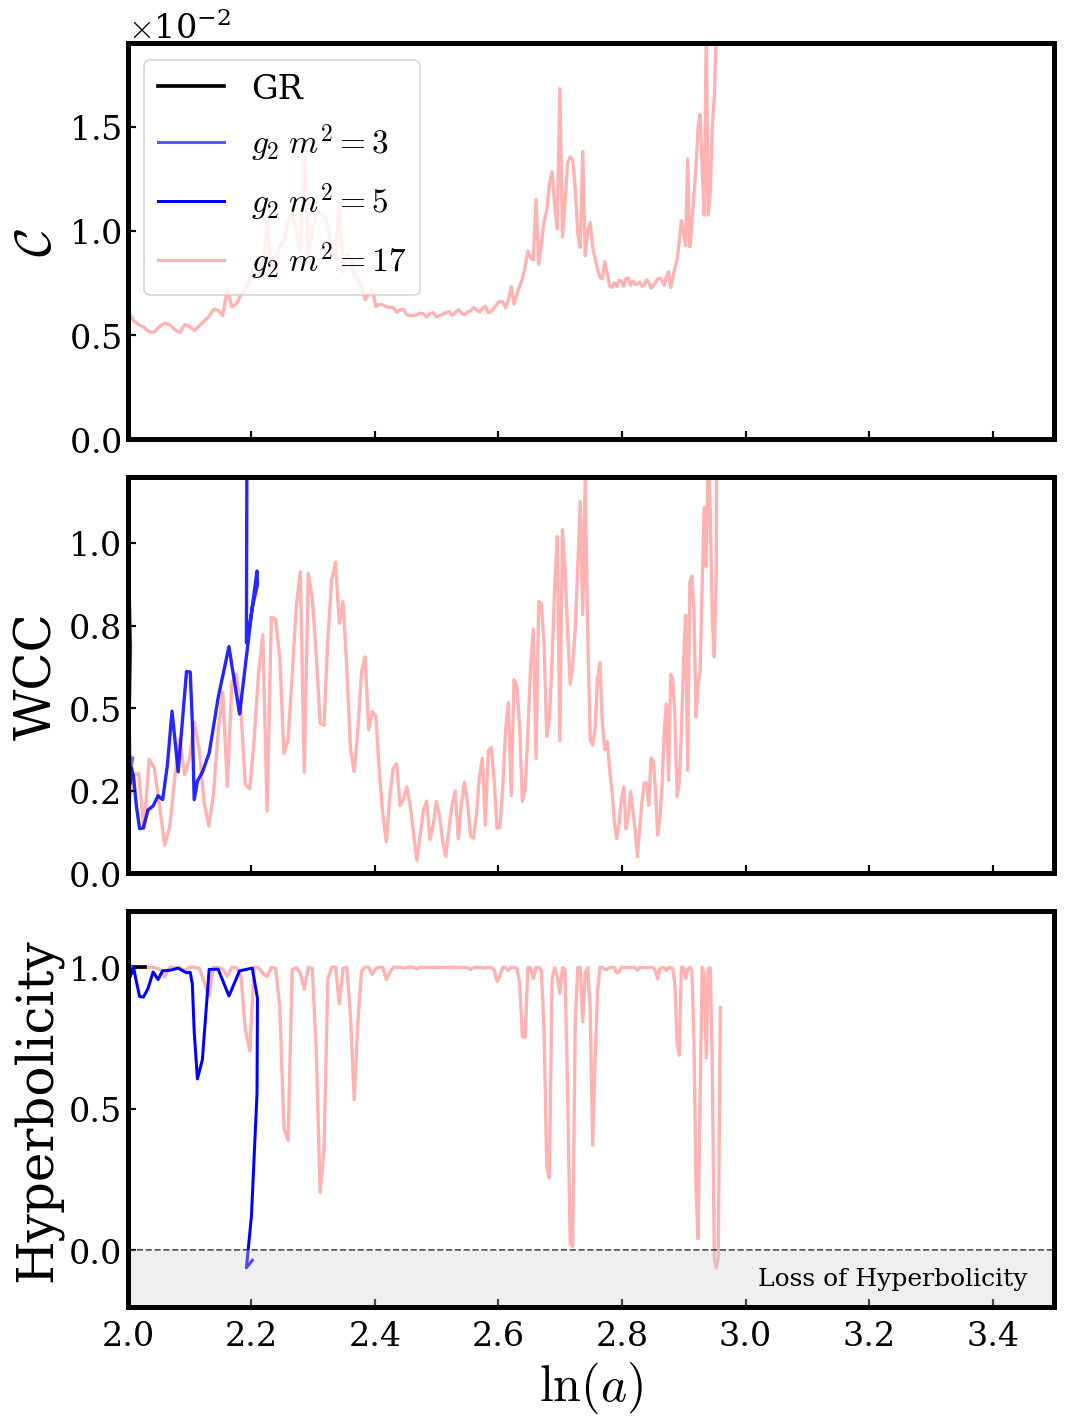


===== three-stack: tot =====


KeyError: 'massdefs'

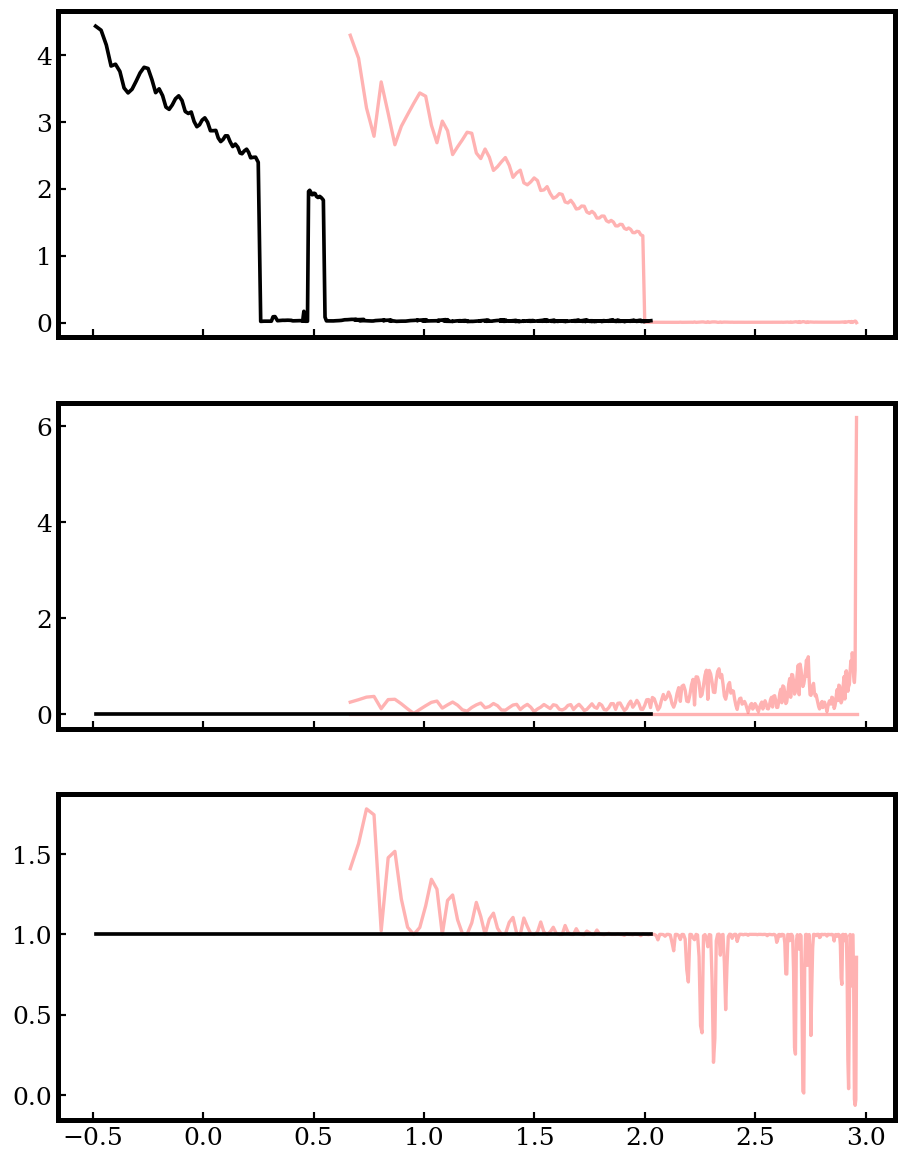

In [14]:
for MASS_DEF in ("phi", "tot", "ms"):
    print("\n===== three-stack: " + MASS_DEF + " =====")
    fig, axes = plt.subplots(3, 1, figsize=(9, 12), sharex=True)

    # Curves coloured by g2 magnitude: light blue = weak g2, dark blue = strong g2.
    # The darkest shade is the matplotlib named colour "blue" (matching the blue
    # used in Panel 4d's right axes) and is assigned to the *highest* selected g2.
    # GR (lgb=0, g2=0) still overrides to black.
    from matplotlib.colors import LinearSegmentedColormap as _LSC
    _unique_g2  = sorted({k[5] for k in PLOT4_KEYS})
    #_BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
    _BLUES_RAMP = _LSC.from_list("_g2_blues", ["#fafbfc", "blue"])
    _TAB10 = plt.cm.tab10

    def _color_for_g2(g2_val):
        if PLOT4_USE_TAB_COLORS:
            rank = _unique_g2.index(g2_val)
            return _TAB10(rank % 10)
        if len(_unique_g2) <= 1:
            return _BLUES_RAMP(1.0)
        rank = _unique_g2.index(g2_val)
        frac = 0.30 + 0.70 * rank / (len(_unique_g2) - 1)
        return _BLUES_RAMP(frac)

    def _rmask_for_eft(eft, r_cut=R_WCC_MAX):
        """Build (r > 0) & (r <= r_cut) from this run's own eft["r"], so runs
        with different grids (e.g. different r_max) don't share a mask."""
        if eft is None or "r" not in eft:
            return None
        r = np.asarray(eft["r"])
        return (r > 0) & (r <= r_cut)

    if len(PLOT4_KEYS) == 0:
        print("No keys selected for Panel 4.")
    else:
        # Draw highlighted run first (behind everything) if requested
        _highlight_legend_handle = None
        if PLOT4_HIGHLIGHT_KEY is not None and PLOT4_HIGHLIGHT_KEY in all_runs:
            _hk  = PLOT4_HIGHLIGHT_KEY
            _hr  = all_runs[_hk]
            _ho  = _hr["osc"]
            _he  = _hr.get("eft", None)
            _hx  = _hr["shifted_ln_a"]
            _h_rmask = _rmask_for_eft(_he)
            _hlgb, _hmu, _hbeta, _hamp, _hwidth, _hg2 = _hk
            _hlbl = rf"$g_2\;m^2={_hg2/2:g}$"
            _hl, = axes[0].plot(_hx, _mass_series(_hr, "C"), color=PLOT4_HIGHLIGHT_COLOR,
                         lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                         zorder=1)
            _highlight_legend_handle = (_hl, _hlbl)
            if _he is not None and _h_rmask is not None:
                _hwc = np.nanmax(_he["wc_lambda_bare"][:, _h_rmask], axis=1)
                axes[1].plot(_hx, _hwc, color=PLOT4_HIGHLIGHT_COLOR,
                             lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                             zorder=1)
                if _hg2 != 0 and "wc_g2_bare" in _he:
                    _hwcg2 = np.nanmax(_he["wc_g2_bare"][:, _h_rmask], axis=1)
                    axes[1].plot(_hx, _hwcg2, color=PLOT4_HIGHLIGHT_COLOR,
                                 lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                                 ls="-", zorder=1)
            if _he is not None and "disc_g2" in _he and _h_rmask is not None:
                _hdisc = np.nanmin(_he["disc_g2"][:, _h_rmask], axis=1)
                axes[2].plot(_hx, _hdisc, color=PLOT4_HIGHLIGHT_COLOR,
                             lw=PLOT4_HIGHLIGHT_LW, alpha=PLOT4_HIGHLIGHT_ALPHA,
                             zorder=1)

        for i, key in enumerate(PLOT4_KEYS):
            run = all_runs[key]
            osc = run["osc"]
            eft = run.get("eft", None)
            lgb, mu, beta, amp, width, g2 = key

            is_gr = (lgb == 0.0 and g2 == 0.0)
            beta_str = rf", \beta={int(beta)}" if (beta is not None and beta != 250) else ""
            g2_str   = rf"g_2\;m^2={g2/2:g}"
            if is_gr:
                label = "GR"
            else:
                label = rf"${g2_str}$"
            if is_gr:
                color = "k"
            elif PLOT4_USE_TAB_COLORS:
                color = _TAB10(i % 10)
            else:
                color = _color_for_g2(g2)
            lw    = 2.2 if is_gr else 1.8

            x = run["shifted_ln_a"]
            r_mask_run = _rmask_for_eft(eft)

            # Panel 0: compactness
            axes[0].plot(x, _mass_series(run, "C"), color=color, lw=lw, label=label, zorder=5)

            # Panel 1: weak-coupling conditions (need eft data)
            if eft is not None and r_mask_run is not None:
                wc_lam = np.nanmax(eft["wc_lambda_bare"][:, r_mask_run], axis=1)
                axes[1].plot(x, wc_lam, color=color, lw=lw, label=label, zorder=5)
                if g2 != 0 and "wc_g2_bare" in eft:
                    wc_g2 = np.nanmax(eft["wc_g2_bare"][:, r_mask_run], axis=1)
                    axes[1].plot(x, wc_g2, color=color, lw=2, ls="-", alpha=0.85, zorder=5)

            # Panel 2: g2 hyperbolicity
            if eft is not None and "disc_g2" in eft and r_mask_run is not None:
                disc_g2_min = np.nanmin(eft["disc_g2"][:, r_mask_run], axis=1)
                axes[2].plot(x, disc_g2_min, color=color, lw=lw, label=label, zorder=5)

        axes[0].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
        axes[0].set_ylabel(r"$\mathcal{C}$", fontsize=30)

        #axes[0].set_title(r"Compactness $\mathcal{C}$")
        #axes[0].grid(False, alpha=0.3)
        axes[0].set_ylim(0, 0.019)

        #axes[1].axhline(1.0, color="k", lw=1.0, ls=":", alpha=0.7)
        axes[1].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
        #axes[1].set_ylabel(r"$\max_r\,\sqrt{|\mathrm{coupling}|}\,\cdot\, \tilde L^{-1}$")
        #axes[1].set_ylabel(r"$\max_r\,\sqrt{|g_2|}\,\cdot\, \tilde L^{-1}$")
        
        
        #axes[1].set_ylabel(r"$\sqrt{|g_2(\phi)|}\,\cdot\, \tilde L^{-1}$",fontsize=30)
        axes[1].set_ylabel(r"WCC",fontsize=30)


        #axes[1].set_title(r"Weak-coupling condition") #(GB length scale $L^{-1}$; $g_2$ length scale $\tilde L^{-1}$, dashed)")
        if PLOT4_WCC_LOG:
            axes[1].set_yscale("linear")
            axes[1].set_ylim(0,1.2)
        else:
            axes[1].set_yscale("linear")
            axes[1].set_ylim(*PLOT4_WCC_YLIM_LINEAR)
        #axes[1].grid(False, alpha=0.3)

        axes[2].axhline(0.0, color="k", lw=1.0, ls="--", alpha=0.8)
        axes[2].axvline(ALIGN_LNA, color="grey", ls=":", lw=1.2, alpha=0.6)
        
        #axes[2].set_ylabel(r"$\dfrac{\det(g^{\rm eff}_{\mu\nu})}{\det(g_{\mu\nu})}$",fontsize=30)
        axes[2].set_ylabel(r"Hyperbolicity",fontsize=30)
        #axes[2].set_title(r"$g_2$ hyperbolicity") # (min over $r$)")

        #axes[1].axhline(0.5, color="k", lw=1.0, ls="--", alpha=0.7)
        from matplotlib.transforms import blended_transform_factory
        _trans1 = blended_transform_factory(axes[1].transAxes, axes[1].transData)
        #axes[1].text(0.8, 4, "Outside of EFT regime", transform=_trans1,va="center", ha="left", fontsize=9, color="black", zorder=11)

        axes[2].axhspan(0, -1, facecolor="lightgrey", alpha=0.35, zorder=10)
        from matplotlib.transforms import blended_transform_factory
        _trans1 = blended_transform_factory(axes[2].transAxes, axes[2].transData)
        axes[2].text(0.68, -0.1, "Loss of Hyperbolicity", transform=_trans1,va="center", ha="left", fontsize=15, color="black", zorder=11)
    



        axes[2].set_ylim(-0.2,1.2)
        #axes[2].grid(False, alpha=0.3)

        axes[2].set_xlabel(r"$\ln(a)$", fontsize=30)
        # shared x across all three rows via sharex=True
        axes[0].set_xlim(2, 3.5)

        # Build legend: main curves sorted by g2, then highlighted run last
        _handles, _labels = axes[0].get_legend_handles_labels()
        if _highlight_legend_handle is not None:
            _leg_handles = _handles
            _leg_labels  = _labels
            _leg_handles.append(_highlight_legend_handle[0])
            _leg_labels.append(_highlight_legend_handle[1])
        else:
            _leg_handles = _handles
            _leg_labels  = _labels
        axes[0].legend(_leg_handles, _leg_labels, fontsize=20, ncol=1, loc="upper left")
        #axes[1].legend(fontsize=13, ncol=1, loc="upper left")
        #axes[2].legend(fontsize=13, ncol=1, loc="upper left")



        from matplotlib.ticker import ScalarFormatter
        class _FixedOrderFormatter(ScalarFormatter):
        
            def __init__(self, order=0, **kwargs):
                self._fixed_order = order
                super().__init__(**kwargs)
            def _set_order_of_magnitude(self):
                self.orderOfMagnitude = self._fixed_order
    
        _PLOT8_ORDER = -2
        _fmtL = _FixedOrderFormatter(order=_PLOT8_ORDER, useMathText=True)
        _fmtL.set_scientific(True)
        _fmtL.set_powerlimits((_PLOT8_ORDER, _PLOT8_ORDER))
        axes[0].yaxis.set_major_formatter(_fmtL)
        axes[0].yaxis.get_offset_text().set_fontsize(20)



        # Ensure axes borders (spines) are drawn on top of all data
        for ax in axes:
            ax.tick_params(which="both", top=False, right=False, labelsize=20)
            ax.tick_params(axis="x", which="both", pad=8)
            ax.set_axisbelow(False)
            for spine in ax.spines.values():
                spine.set_zorder(20)

        # Gradient shading in panel 1: lightgrey at y=0.5 fading to white as y increases.
        # Placed after axes[0].set_xlim so extent matches the final displayed x-range.
        '''
        from matplotlib.colors import LinearSegmentedColormap as _LSC_grad
        _eft_grad_cmap = _LSC_grad.from_list(
            "_eft_grad",
            [(1.0, 1.0, 1.0, 1.0),(0.827, 0.827, 0.827, 1)]
        )
        _x0, _x1 = axes[1].get_xlim()
        _y0, _y1 = axes[1].get_ylim()
        _grad = np.linspace(0.0, 1.0, 512).reshape(-1, 1)
        axes[1].imshow(
            _grad, aspect="auto", cmap=_eft_grad_cmap,
            extent=[_x0, _x1, 0.05, _y1], origin="lower",
            interpolation="bilinear", zorder=0,
        )
        # imshow can nudge limits; restore
        axes[1].set_xlim(_x0, _x1)
        axes[1].set_ylim(_y0, _y1)
        '''

        from matplotlib.ticker import FormatStrFormatter

        axes[2].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        axes[1].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        '''
        #_eft_x = np.arange(0.5, 1, 0.03)
        _eft_x = np.arange(0.55, 1.3, 0.03)
        colors = plt.cm.Greys(np.linspace(0, 0.6, len(_eft_x)))
        for i in range(len(_eft_x)):
            axes[1].axhline(_eft_x[i], color=colors[i], ls="-", lw=1.7, zorder=0.2)
        '''
        '''
        _eft_x = np.arange(
            5,
            12,
            0.15)

        cmap = plt.cm.Greys

        norm = Normalize(
            vmin=_eft_x.min(),
            vmax=_eft_x.max()
        )
        sm = ScalarMappable(
        norm=norm,
        cmap=cmap
        )

        sm.set_array([])

        # [left, bottom, width, height]
        # all relative to the right-hand axes
        cax = axes[1].inset_axes(
            [
                0.9,0.3,0.02,0.6
            ]
        )


        cbar = fig.colorbar(
            sm,
            cax=cax,
            orientation="vertical"
        )


        cbar.set_ticks(
            []
        )

        cbar.ax.tick_params(
            axis="x",
            labelsize=8,
            length=3,
            pad=5
        )

        cbar.set_label(
            r"Departure EFT Regime",
            fontsize=8,
            labelpad=-50
        )
        cbar.outline.set_linewidth(1)

        cbar.ax.annotate(
            "",
            xy=(0.5, 0.7),      # arrow head
            xytext=(0.5, 0.1),  # arrow start
            xycoords="axes fraction",
            arrowprops=dict(
                arrowstyle="->",
                color="white",
                lw=1.0
            ),
            zorder=10
        )
        ''' 

        fig.tight_layout()
        save_fig(fig, PLOT4_NAME + "_grad_M" + MASS_DEF)
        plt.show()


## Scalar gradients and $|\mathcal{G}|^{1/4}$

One time series on the aligned window $\ln(a)\in[2,\,3.5]$.

- $g_2=10$, $\lambda_{\rm GB}=0$: $|\nabla_\mu\nabla_\nu\phi|^{1/2}=I_2^{1/4}$, together with the two gradients that enter the $g_2$ length scale, $|K_\phi|=|n^\mu\nabla_\mu\phi|$ and $|D_i\phi|$.
- $\lambda_{\rm GB}=5$, $g_2=0$: $|\mathcal{G}|^{1/4}$.

Both runs use $\beta=0$, $\mu=0.08$, $A=-0.02$, $R=3$. Each curve is $\max_{0<r\leq 100}$. The solid line is the peak envelope over one oscillation; the faint line is the raw signal.

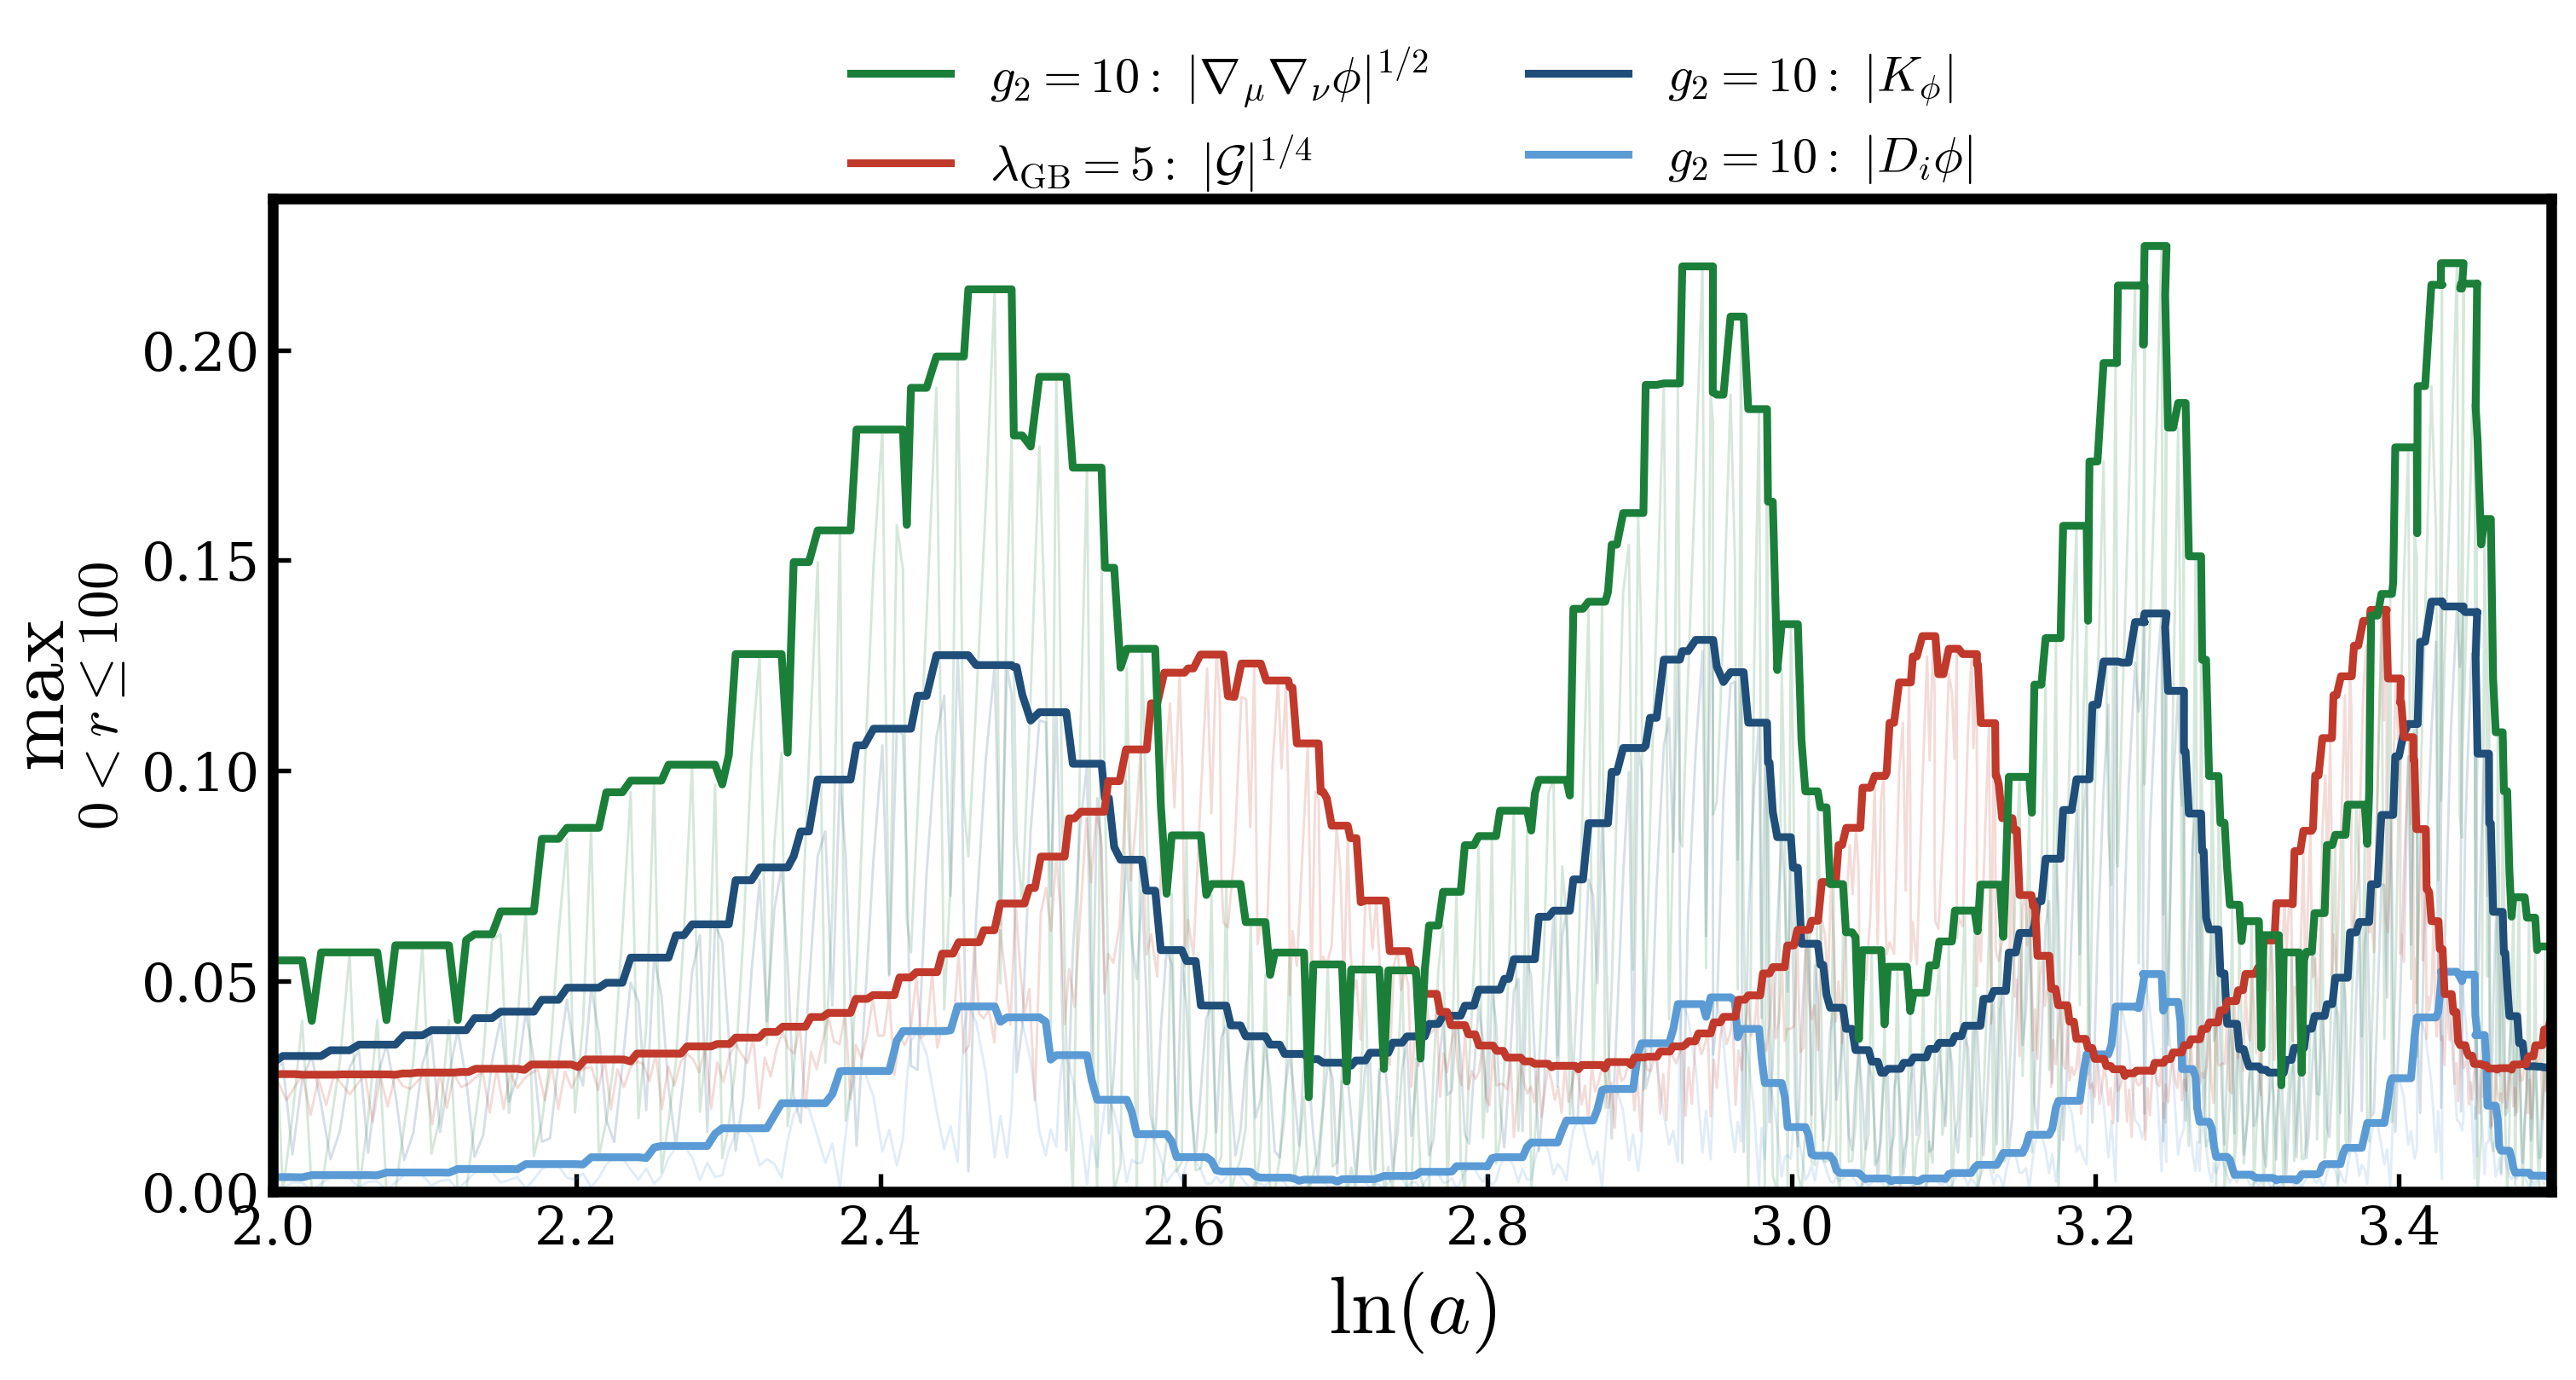

In [ ]:
def _load_eft(key):
    """Load cached eft_diagnostics.npz onto the run if it is not already there."""
    d = all_runs[key]
    if "eft" in d:
        return d["eft"]
    eft_path = os.path.join(d["run_dir"], "eft_diagnostics.npz")
    d["eft"] = dict(np.load(eft_path, allow_pickle=True))
    print(f"  [EFT] loaded cache for {d['tag']}")
    return d["eft"]


def _max_over_r(eft, name, r_cut=100.0):
    r = np.asarray(eft["r"])
    mask = (r > 0.0) & (r <= r_cut)
    return np.nanmax(np.asarray(eft[name])[:, mask], axis=1)


def _upper_envelope(y, x, full_width=0.012):
    """Centered running maximum. full_width is one oscillon period in ln(a)."""
    dx = float(np.median(np.diff(x)))
    half = max(1, int(round(0.5 * full_width / dx)))
    padded = np.pad(y, half, mode="edge")
    windows = np.lib.stride_tricks.sliding_window_view(padded, 2 * half + 1)
    return np.nanmax(windows, axis=1)


_g2_keys = select_runs(lgb=0, mu=0.08, beta=0, amp=-0.02, width=3.0, g2=10)
_gb_keys = select_runs(lgb=5, mu=0.08, beta=0, amp=-0.02, width=3.0, g2=0)
if len(_g2_keys) != 1 or len(_gb_keys) != 1:
    raise RuntimeError(f"expected one run each, got g2={_g2_keys}, GB={_gb_keys}")
_g2_key, _gb_key = _g2_keys[0], _gb_keys[0]
print("g2 run:", all_runs[_g2_key]["tag"])
print("GB run:", all_runs[_gb_key]["tag"])

_curves = [
    # (run key, eft array, legend, colour, zorder) — drawn back to front
    (_g2_key, "grad_phi_spatial", r"$g_2=10:\ |D_i\phi|$",                       "#5b9bd5", 2),
    (_g2_key, "K_phi",            r"$g_2=10:\ |K_\phi|$",                        "#1f4e79", 3),
    (_gb_key, "term_gb_quarter",  r"$\lambda_{\rm GB}=5:\ |\mathcal{G}|^{1/4}$", "#c0392b", 4),
    (_g2_key, "term_hess_u_sqrt", r"$g_2=10:\ |\nabla_\mu\nabla_\nu\phi|^{1/2}$","#1b7f3a", 5),
]

fig, ax = plt.subplots(figsize=(10.2, 5.6))
_handles = []
for key, name, label, color, z in _curves:
    run = all_runs[key]
    eft = _load_eft(key)
    x = np.asarray(run["shifted_ln_a"], dtype=float)
    y = _max_over_r(eft, name)
    env = _upper_envelope(y, x)
    w = (x >= LN_A_COMP_MIN) & (x <= LN_A_COMP_MAX)
    ax.plot(x[w], y[w], color=color, lw=0.7, alpha=0.18, zorder=z)
    line, = ax.plot(x[w], env[w], color=color, lw=2.2, zorder=z + 10, label=label)
    _handles.append(line)
    print(f"  {label}: envelope median {np.nanmedian(env[w]):.4f}, max {np.nanmax(env[w]):.4f}")

_order = [3, 2, 1, 0]
ax.legend(
    [_handles[i] for i in _order],
    [_curves[i][2] for i in _order],
    loc="upper center", bbox_to_anchor=(0.5, 1.20),
    ncol=2, frameon=False, fontsize=14,
)
ax.set_xlim(LN_A_COMP_MIN, LN_A_COMP_MAX)
ax.set_ylim(bottom=0.0)
ax.set_xlabel(r"$\ln(a)$")
ax.set_ylabel(r"$\max_{0<r\leq 100}$")
for spine in ax.spines.values():
    spine.set_zorder(20)
fig.tight_layout()
save_fig(fig, "gradient_scales_g2_10_lgb5")
plt.show()

## Scalar gradients across $g_2$

Same aligned window and radial maximum as the figure above, without $|\mathcal{G}|^{1/4}$. Colour is the $g_2$ coupling and line style is the gradient. Edit `SEL_G2` and `SEL_GRADS` in the cell below.

available g2: [-20.0, -18.0, -16.0, -14.0, -12.0, -10.0, -8.0, -6.0, -4.0, -2.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 25.0, 30.0, 35.0]
g2=0: lgb0.0_mu0.08_a0.0_b0.0_amp-0.02_R3.0_dr0.041666666666666664_quadratic_0
g2=10: lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g210
g2=20: lgb0_mu0.08_a0_b0_amp-0.02_R3_dr0.0416667_quadratic_0_g220
  saved gradient_scales_vs_g2.pdf and gradient_scales_vs_g2.png


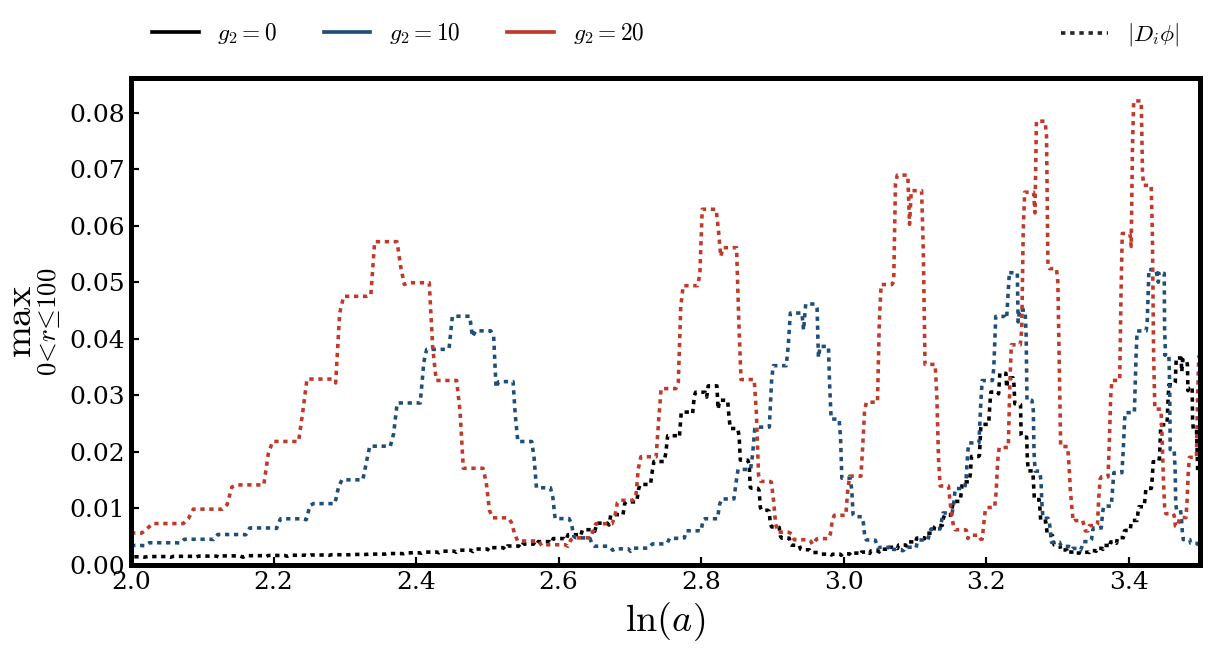

In [84]:
### --- g2 gradient comparison (edit me) ---
# Which g2 couplings to draw. Only runs that exist are kept.
SEL_G2 = [0, 10, 20]

# Which gradients to draw. Any subset of:
#   hess     |nabla_mu nabla_nu phi|^{1/2}
#   K_phi    |K_phi|
#   spatial  |D_i phi|
#   grad_u   |nabla_mu phi|   (kinetic contraction)

#SEL_GRADS = ["hess", "K_phi", "spatial"]
SEL_GRADS = ["spatial"]

# Shared run parameters. lambda_GB stays 0 so the Gauss-Bonnet invariant is absent.
SEL_LGB   = 0
SEL_MU    = 0.08
SEL_BETA  = 0
SEL_AMP   = -0.02
SEL_WIDTH = 3.0

# True draws the raw oscillon oscillation under each envelope.
SHOW_RAW = False


_GRAD_CATALOG = {
    "hess":    ("term_hess_u_sqrt", r"$|\nabla_\mu\nabla_\nu\phi|^{1/2}$", "-"),
    "K_phi":   ("K_phi",            r"$|K_\phi|$",                        (0, (5, 1.6))),
    "spatial": ("grad_phi_spatial", r"$|D_i\phi|$",                       (0, (1.2, 1.3))),
    "grad_u":  ("term_grad_u",      r"$|\nabla_\mu\phi|$",                (0, (3, 1.2, 1, 1.2))),
}
_unknown = [name for name in SEL_GRADS if name not in _GRAD_CATALOG]
if _unknown:
    raise ValueError(f"unknown gradient(s) {_unknown}; choose from {list(_GRAD_CATALOG)}")

_pool = select_runs(
    lgb=SEL_LGB, mu=SEL_MU, beta=SEL_BETA,
    amp=SEL_AMP, width=SEL_WIDTH,
)
_by_g2 = {k[5]: k for k in _pool}
print("available g2:", [g for g in sorted(_by_g2)])
_missing = [g for g in SEL_G2 if g not in _by_g2]
if _missing:
    print("skipped, no run:", _missing)
_g2_plot = [g for g in SEL_G2 if g in _by_g2]
if not _g2_plot:
    raise RuntimeError("none of SEL_G2 matched a loaded run")

def _load_eft(key):
    d = all_runs[key]
    if "eft" in d:
        return d["eft"]
    eft_path = os.path.join(d["run_dir"], "eft_diagnostics.npz")
    d["eft"] = dict(np.load(eft_path, allow_pickle=True))
    print(f"  [EFT] loaded cache for {d['tag']}")
    return d["eft"]

def _max_over_r(eft, name, r_cut=100.0):
    r = np.asarray(eft["r"])
    mask = (r > 0.0) & (r <= r_cut)
    return np.nanmax(np.asarray(eft[name])[:, mask], axis=1)

def _upper_envelope(y, x, full_width=0.012):
    """Centered running maximum. full_width is one oscillon period in ln(a)."""
    dx = float(np.median(np.diff(x)))
    half = max(1, int(round(0.5 * full_width / dx)))
    padded = np.pad(y, half, mode="edge")
    windows = np.lib.stride_tricks.sliding_window_view(padded, 2 * half + 1)
    return np.nanmax(windows, axis=1)

_palette = ["#1f4e79", "#c0392b", "#1b7f3a", "#d35400", "#6c3483", "#117a65", "#1a5276", "#b7950b"]
_nonzero = [g for g in _g2_plot if g != 0]
_color_of = {
    g: ("k" if g == 0 else _palette[_nonzero.index(g) % len(_palette)])
    for g in _g2_plot
}

from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(10.2, 5.6))
for g2 in _g2_plot:
    key = _by_g2[g2]
    run = all_runs[key]
    eft = _load_eft(key)
    x = np.asarray(run["shifted_ln_a"], dtype=float)
    w = (x >= LN_A_COMP_MIN) & (x <= LN_A_COMP_MAX)
    print(f"g2={g2:g}: {run['tag']}")
    for name in SEL_GRADS:
        arr, latex, ls = _GRAD_CATALOG[name]
        y = _max_over_r(eft, arr)
        env = _upper_envelope(y, x)
        if SHOW_RAW:
            ax.plot(x[w], y[w], color=_color_of[g2], ls=ls, lw=0.6, alpha=0.15, zorder=2)
        ax.plot(x[w], env[w], color=_color_of[g2], ls=ls, lw=2.15, zorder=3)

_color_handles = [
    Line2D([0], [0], color=_color_of[g], lw=2.2, ls="-") for g in _g2_plot
]
_style_handles = [
    Line2D([0], [0], color="0.15", lw=2.2, ls=_GRAD_CATALOG[name][2]) for name in SEL_GRADS
]
_leg_g2 = ax.legend(
    _color_handles, [rf"$g_2={g:g}$" for g in _g2_plot],
    loc="upper left", bbox_to_anchor=(0.0, 1.16),
    ncol=min(4, len(_g2_plot)), frameon=False, fontsize=14,
)
ax.add_artist(_leg_g2)
ax.legend(
    _style_handles, [_GRAD_CATALOG[name][1] for name in SEL_GRADS],
    loc="upper right", bbox_to_anchor=(1.0, 1.16),
    ncol=min(3, len(SEL_GRADS)), frameon=False, fontsize=14,
)
ax.set_xlim(LN_A_COMP_MIN, LN_A_COMP_MAX)
ax.set_ylim(bottom=0.0)
ax.set_xlabel(r"$\ln(a)$")
ax.set_ylabel(r"$\max_{0<r\leq 100}$")
for spine in ax.spines.values():
    spine.set_zorder(20)
fig.tight_layout()
save_fig(fig, "gradient_scales_vs_g2")
plt.show()